# TP — Chaînes de déploiement d'un modèle d'IA
## Pipeline CPU n°2 : PyTorch → TorchScript / torch.compile → CPU

| Niveau | Composant | Rôle dans ce notebook |
|---|---|---|
| **Haut niveau** | PyTorch | ResNet-18 pré-entraîné ImageNet, tête 10 classes (section 1) |
| **Format du modèle** | graphe **TorchScript** (IR statique) · graphe **PyTorch 2 / FX** capturé par TorchDynamo | capture du graphe de calcul (4.1, 5.1) |
| **Middle level** | passes d'optimisation TorchScript · compilateur **Inductor** | gel des poids, repliement BatchNorm, fusion, génération de code (4, 5) |
| **Bas niveau** | kernels oneDNN (convolutions) + **code C++ vectorisé / OpenMP** généré par Inductor | visibles par profilage (section 6) |
| **Matériel** | CPU de Google Colab | 2 vCPU, environnement d'exécution « CPU » |

**Modèle** : ResNet-18 pré-entraîné ImageNet, 10 classes · **Données** : 50 images de test CIFAR-10 (5 par classe) · **Batch** : 10 · **Répétitions** : 10 passes mesurées + 3 mesures d'énergie.

### Avant de lancer
1. `Exécution` → `Modifier le type d'exécution` → **CPU** (même type que pour le notebook OpenVINO).
2. `Exécution` → `Tout exécuter` et autoriser Google Drive (dossier `MyDrive/TP_Deploiement_IA`, partagé avec l'autre notebook).
3. Durée : ≈ 10–15 min (dont 1–3 min de compilation `torch.compile` par variante).

### Plan
0. Environnement · 1. Préparation commune · 2. Outils de mesure · 3. Référence PyTorch eager · 4. TorchScript · 5. torch.compile (Inductor) · 6. Profilage bas niveau · 7. Résultats de ce pipeline · 8. Comparaison des pipelines · 9. Analyse

## 0. Environnement
### 0.1 Installation
PyTorch est déjà installé sur Colab. `psutil` mesure le temps CPU ; `onnx` n'est pas nécessaire ici. Inductor a besoin d'un compilateur C++ (`g++`, présent sur Colab).

In [ ]:
!pip install -q psutil
!g++ --version | head -1
!lscpu | grep -E "Model name|^CPU\(s\)|Thread|Core\(s\)|Socket|L3" ; grep -o -w -E "avx2|avx512f|avx512_vnni|amx_tile|avx512_bf16" /proc/cpuinfo | sort -u | tr "\n" " "

g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
Thread(s) per core:                      2
Core(s) per socket:                      1
Socket(s):                               1
L3 cache:                                55 MiB (1 instance)
avx2 

### 0.2 Configuration de l'expérience
Les paramètres expérimentaux sont **identiques dans les deux notebooks** (images, batch, warm-up, répétitions, threads, énergie).

In [ ]:
import os, json, time, math, copy, hashlib, datetime, warnings
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=UserWarning)

# ---------- Paramètres expérimentaux : IDENTIQUES dans les deux notebooks ----------
SEED = 42
N_IMAGES = 50            # images de test CIFAR-10
BATCH_SIZE = 10          # => 5 batches par passe
N_WARMUP = 5             # passes complètes non mesurées
N_RUNS = 10              # passes mesurées (>= 3 exigées)
ENERGY_MIN_SECONDS = 10.0
N_ENERGY_REPS = 3
N_THREADS = os.cpu_count()          # tous les vCPU, pour chaque moteur
CPU_POWER_PER_VCPU_W = 10.0         # HYPOTHÈSE utilisée seulement si RAPL est inaccessible

# ---------- Adaptation du modèle à 10 classes (si les poids n'existent pas encore) ----------
N_TRAIN_PER_CLASS = 300  # images d'entraînement par classe pour le linear probing
N_VAL = 500              # images de test (hors des 50) pour estimer la précision du modèle

# ---------- Stockage partagé par les deux notebooks (Google Drive) ----------
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/TP_Deploiement_IA"
else:
    ROOT = "/content/TP_Deploiement_IA"
SHARED, RESULTS, FIGS, WORK = f"{ROOT}/shared", f"{ROOT}/results", f"{ROOT}/figures", "/content/work"
for d in (SHARED, RESULTS, FIGS, WORK):
    os.makedirs(d, exist_ok=True)

PIPELINE_TAG = "pt"
SESSION_ID = PIPELINE_TAG + "_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
torch.manual_seed(SEED); np.random.seed(SEED)
torch.set_num_threads(N_THREADS)
if torch.cuda.is_available():
    print("⚠ Un GPU est attaché : choisissez un environnement CPU pour des mesures comparables.")
print("Session :", SESSION_ID, "| threads :", N_THREADS, "| dossier :", ROOT)

RUN_MAX_AUTOTUNE = False   # variante optionnelle torch.compile(mode="max-autotune") : compilation bien plus longue
SESSION_REF_KEY = "cpu_pt_ref_eager"

Mounted at /content/drive
Session : pt_20261116-104050 | threads : 2 | dossier : /content/drive/MyDrive/TP_Deploiement_IA


### (Optionnel) Sans Google Drive : importer l'archive produite par l'autre notebook
Seulement si `USE_DRIVE = False` et que l'autre notebook a déjà été exécuté : importez `TP_Deploiement_IA.zip` (dernière cellule de l'autre notebook). Sinon, ignorez cette cellule.

In [ ]:
if not USE_DRIVE and not os.path.exists(f"{SHARED}/cifar10_test50.pt"):
    import zipfile
    from google.colab import files
    print("Importez TP_Deploiement_IA.zip (ou annulez si c'est le premier notebook exécuté).")
    try:
        up = files.upload()
        with zipfile.ZipFile(next(iter(up))) as z:
            z.extractall(ROOT)
    except Exception as e:
        print("Aucune archive importée :", e)

### 0.3 Informations sur l'environnement (enregistrées avec chaque résultat)

In [ ]:
import os, platform, subprocess

def _cpu_model():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor()

def get_env_info():
    import torch, torchvision
    info = {"python": platform.python_version(), "torch": torch.__version__,
            "torchvision": torchvision.__version__, "cpu": _cpu_model(), "n_vcpu": os.cpu_count(),
            "torch_threads": torch.get_num_threads()}
    if torch.cuda.is_available():
        info.update({"cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
                     "gpu": torch.cuda.get_device_name(0),
                     "compute_capability": ".".join(map(str, torch.cuda.get_device_capability(0)))})
        try:
            info["nvidia_driver"] = subprocess.check_output(
                ["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"]).decode().strip()
        except Exception:
            pass
    return info

ENV = get_env_info()
ENV["mkldnn_disponible"] = torch.backends.mkldnn.is_available()
ENV["config_parallele"] = torch.__config__.parallel_info().splitlines()[:6]
for k, v in ENV.items():
    print(f"{k:>20} : {v}")

              python : 3.13.18
               torch : 2.14.1+cpu
         torchvision : 0.29.1+cpu
                 cpu : Intel(R) Xeon(R) CPU @ 2.20GHz
              n_vcpu : 2
       torch_threads : 2
   mkldnn_disponible : True
    config_parallele : ['ATen/Parallel:', '\tat::get_num_threads() : 2', '\tat::get_num_interop_threads() : 1', 'OpenMP 201511 (a.k.a. OpenMP 4.5)', '\tomp_get_max_threads() : 2', 'Intel(R) oneAPI Math Kernel Library Version 2024.2-Product Build 20240605 for Intel(R) 64 architecture applications']


## 1. Préparation commune : modèle et données (identique dans les deux notebooks)

Cette section est **la même dans les deux notebooks**. Le premier notebook exécuté crée les fichiers dans `Drive/TP_Deploiement_IA/shared` ; le second les **recharge** au lieu de les recréer. Les deux pipelines utilisent donc exactement le même modèle et les mêmes octets d'entrée (contrôle par empreinte SHA-256).

**Données** : 50 images du jeu de **test** CIFAR-10, tirées avec une graine fixe, **5 par classe** (sous-ensemble équilibré).

**Prétraitement** (fonction unique `preprocess_uint8`) :
1. `uint8 [0,255]` → `float32 [0,1]` ;
2. redimensionnement **32×32 → 224×224** (bilinéaire), résolution d'entraînement de ResNet-18 ;
3. normalisation avec les statistiques ImageNet du pré-entraînement : `mean=(0.485, 0.456, 0.406)`, `std=(0.229, 0.224, 0.225)`.

**Modèle à 10 classes** : ResNet-18 pré-entraîné ImageNet sort 1000 classes. On garde tout le réseau pré-entraîné **gelé** et on remplace la dernière couche `fc` (512 → 1000) par une couche 512 → 10 apprise sur des images d'**entraînement** CIFAR-10 (*linear probing*, ≈ 2–3 min sur CPU). Si un fichier de poids existe déjà dans `shared` (par exemple créé par le notebook GPU d'un binôme), il est réutilisé tel quel.

In [ ]:
# ---------- Modèle et prétraitement (définitions communes) ----------
from torchvision.models import resnet18, ResNet18_Weights

NUM_CLASSES = 10
IMG_SIZE = 224
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

def build_model(num_classes=NUM_CLASSES, pretrained=True):
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m

def preprocess_uint8(x_uint8_nhwc):
    # uint8 [N,32,32,3] -> float32 [N,3,224,224] normalisé ImageNet
    x = x_uint8_nhwc.permute(0, 3, 1, 2).float().div(255.0)
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    mean = torch.tensor(MEAN, device=x.device).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=x.device).view(1, 3, 1, 1)
    return (x - mean) / std

PREPROCESSING = {"resize": [IMG_SIZE, IMG_SIZE], "interpolation": "bilinear, align_corners=False",
                 "scale": "1/255", "mean": list(MEAN), "std": list(STD), "layout": "NCHW float32"}

TEST50_PATH = f"{SHARED}/cifar10_test50.pt"
WEIGHTS_PATH = f"{SHARED}/resnet18_cifar10.pth"
MODEL_INFO_PATH = f"{SHARED}/model_info.json"
ONNX_PATH = f"{SHARED}/resnet18_cifar10.onnx"

train_set = torchvision.datasets.CIFAR10("/content/data", train=True, download=True)
test_set = torchvision.datasets.CIFAR10("/content/data", train=False, download=True)
CLASSES = test_set.classes

100%|██████████| 170M/170M [35:46<00:00, 79.4kB/s]


Sous-ensemble existant rechargé : /content/drive/MyDrive/TP_Deploiement_IA/shared/cifar10_test50.pt
Images : (50, 3, 224, 224) torch.float32 | par classe : [5 5 5 5 5 5 5 5 5 5]
Indices CIFAR-10 (test) : [347, 883, 1020, 1216, 1381, 1626, 1658, 1870, 2285, 2786, 3138, 3316, 3534, 3802, 4064, 4244, 4297, 4374, 4426, 4492, 4542, 4589, 4609, 4623, 4811, 5052, 5217, 5486, 5501, 6056, 6274, 6574, 6733, 6999, 7075, 7450, 7527, 7638, 7662, 7701, 8118, 8181, 8363, 8430, 8452, 8901, 9149, 9651, 9652, 9763]
SHA-256 des entrées : 117a8d622a1424ccdda5f77c957bd3794f6b3a54ff4d94a690b53d19052a30f9


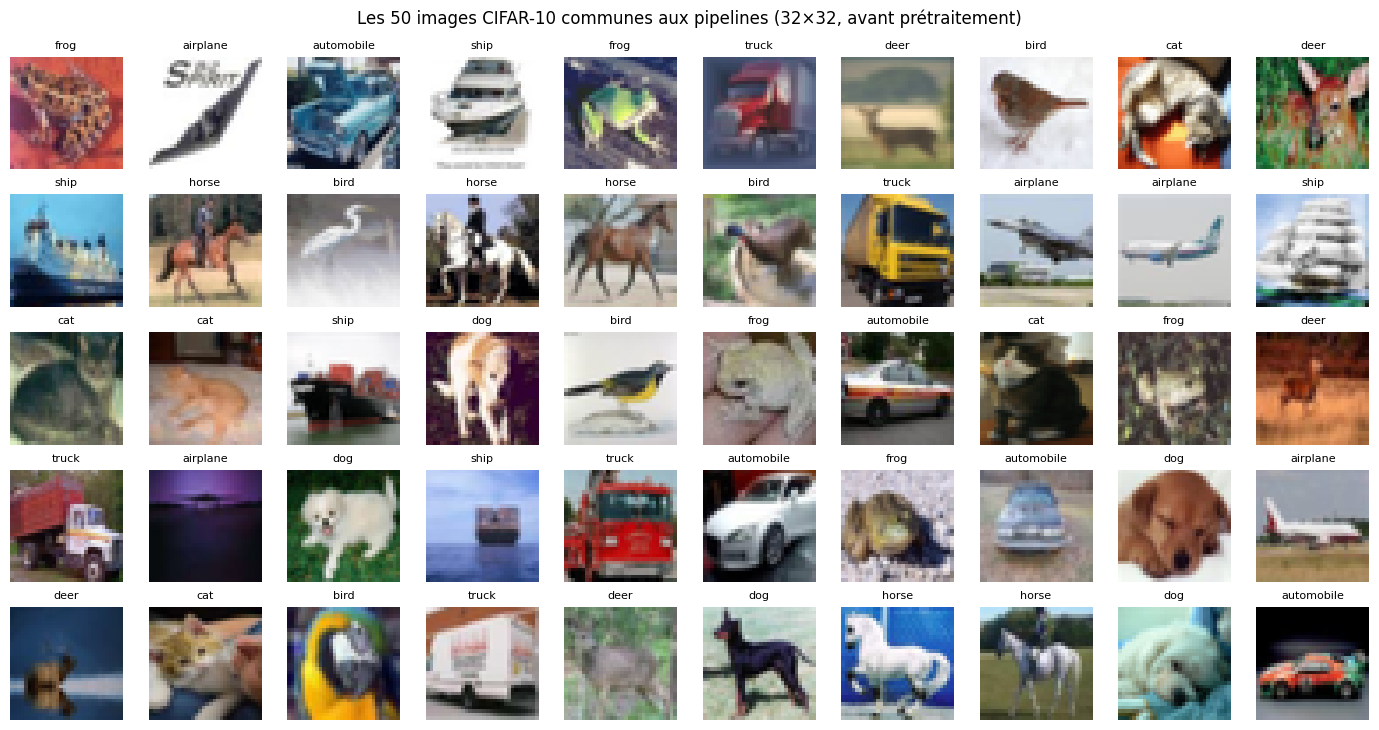

In [ ]:
# ---------- 1.1 Sous-ensemble des 50 images (créé une seule fois, puis rechargé) ----------
if not os.path.exists(TEST50_PATH):
    labels_test = np.array(test_set.targets)
    rng = np.random.default_rng(SEED)
    idx = np.sort(np.concatenate([
        rng.choice(np.where(labels_test == c)[0], N_IMAGES // NUM_CLASSES, replace=False)
        for c in range(NUM_CLASSES)]))
    x50_uint8 = torch.from_numpy(test_set.data[idx])
    y50 = torch.from_numpy(labels_test[idx]).long()
    x50 = preprocess_uint8(x50_uint8).contiguous()
    torch.save({"images": x50, "labels": y50, "images_uint8": x50_uint8, "indices": idx.tolist(),
                "classes": CLASSES, "preprocessing": PREPROCESSING,
                "sha256": hashlib.sha256(x50.numpy().tobytes()).hexdigest()}, TEST50_PATH)
    print("Sous-ensemble créé :", TEST50_PATH)
else:
    print("Sous-ensemble existant rechargé :", TEST50_PATH)

T50 = torch.load(TEST50_PATH, weights_only=False)
X50, Y50 = T50["images"].contiguous(), T50["labels"]
Y50_NP = Y50.numpy()
X50_NP = np.ascontiguousarray(X50.numpy())
TEST_SHA = hashlib.sha256(X50.numpy().tobytes()).hexdigest()
assert TEST_SHA == T50["sha256"], "Empreinte des images incohérente"
assert T50["preprocessing"] == PREPROCESSING, "Paramètres de prétraitement différents"
print("Images :", tuple(X50.shape), X50.dtype, "| par classe :", np.bincount(Y50_NP))
print("Indices CIFAR-10 (test) :", T50["indices"])
print("SHA-256 des entrées :", TEST_SHA)

fig, axes = plt.subplots(5, 10, figsize=(14, 7.4))
for ax, img, lab in zip(axes.ravel(), T50["images_uint8"], Y50_NP):
    ax.imshow(img.numpy()); ax.set_title(CLASSES[lab], fontsize=8); ax.axis("off")
fig.suptitle("Les 50 images CIFAR-10 communes aux pipelines (32×32, avant prétraitement)")
plt.tight_layout(); plt.show()

In [ ]:
# ---------- 1.2 Modèle 10 classes (créé une seule fois, puis rechargé) ----------
@torch.no_grad()
def extract_features(backbone, x_uint8, bs=100):
    out = []
    for i in range(0, len(x_uint8), bs):
        out.append(backbone(preprocess_uint8(torch.from_numpy(x_uint8[i:i + bs]))).flatten(1))
    return torch.cat(out)

if not os.path.exists(WEIGHTS_PATH):
    print("Création de la tête 10 classes par linear probing (réseau pré-entraîné gelé)…")
    torch.manual_seed(SEED)
    model = build_model(pretrained=True).eval()
    backbone = nn.Sequential(*list(model.children())[:-1]).eval()     # tout sauf fc -> [N,512,1,1]
    rng = np.random.default_rng(SEED)
    ytr_all, yte_all = np.array(train_set.targets), np.array(test_set.targets)
    tr_idx = np.sort(np.concatenate([rng.choice(np.where(ytr_all == c)[0], N_TRAIN_PER_CLASS, replace=False)
                                     for c in range(NUM_CLASSES)]))
    pool = np.setdiff1d(np.arange(len(yte_all)), np.array(T50["indices"]))   # jamais les 50 images
    va_idx = np.sort(rng.choice(pool, N_VAL, replace=False))
    t0 = time.time()
    f_tr = extract_features(backbone, train_set.data[tr_idx])
    f_va = extract_features(backbone, test_set.data[va_idx])
    print(f"Extraction des caractéristiques : {time.time() - t0:.0f} s")
    y_tr, y_va = torch.from_numpy(ytr_all[tr_idx]).long(), torch.from_numpy(yte_all[va_idx]).long()
    head = nn.Linear(512, NUM_CLASSES)
    opt = torch.optim.Adam(head.parameters(), lr=1e-2, weight_decay=1e-4)
    for it in range(500):
        opt.zero_grad()
        loss = F.cross_entropy(head(f_tr), y_tr)
        loss.backward(); opt.step()
    with torch.no_grad():
        acc_tr = (head(f_tr).argmax(1) == y_tr).float().mean().item() * 100
        acc_va = (head(f_va).argmax(1) == y_va).float().mean().item() * 100
    print(f"Tête 10 classes : perte {loss.item():.3f} | Top-1 entraînement {acc_tr:.1f} % | validation {acc_va:.1f} %")
    model.fc.load_state_dict(head.state_dict())
    torch.save(model.state_dict(), WEIGHTS_PATH)
    with open(MODEL_INFO_PATH, "w") as f:
        json.dump({"base": "torchvision resnet18 IMAGENET1K_V1 (gelé)", "head": "Linear(512,10)",
                   "method": "linear probing", "train_images": int(len(tr_idx)),
                   "val_images": int(len(va_idx)), "val_top1_pct": acc_va}, f, indent=2)
    del model, backbone, f_tr, f_va
else:
    print("Poids existants rechargés :", WEIGHTS_PATH)

model_ref = build_model(pretrained=False)
model_ref.load_state_dict(torch.load(WEIGHTS_PATH, map_location="cpu"))
model_ref.eval()
if os.path.exists(MODEL_INFO_PATH):
    with open(MODEL_INFO_PATH) as f:
        print("Modèle :", json.load(f))

Poids existants rechargés : /content/drive/MyDrive/TP_Deploiement_IA/shared/resnet18_cifar10.pth
Modèle : {'base': 'torchvision resnet18 IMAGENET1K_V1 (gelé)', 'head': 'Linear(512,10)', 'method': 'linear probing', 'train_images': 3000, 'val_images': 500, 'val_top1_pct': 80.80000281333923}


## 2. Outils de mesure (identiques dans les deux notebooks)

**Protocole commun à tous les pipelines :**
* 50 images → **5 batches de 10**, entrées prétraitées une fois pour toutes (le prétraitement n'est pas chronométré) ;
* **5 passes de warm-up** non mesurées : allocations mémoire, compilation JIT / optimisation de graphe à la volée, remplissage des caches ;
* **10 passes mesurées** (≥ 3 exigées) chronométrées avec `time.perf_counter()` ;
* par passe : **temps d'inférence** des 50 images, **débit** = 50 / temps (images/s), **latence par batch** (moyenne, médiane, max), **précision Top-1**, accord avec la 1re passe ;
* pour chaque indicateur : **moyenne, écart-type, minimum, maximum, coefficient de variation** (CV = σ / moyenne) ;
* chaque exécution complète du notebook est enregistrée dans `results/history/` : relancer le notebook dans une nouvelle session ajoute une **exécution indépendante** (voir la dernière section).

**Énergie CPU** :
* **RAPL** (*Running Average Power Limit*, compteur d'énergie du package CPU dans `/sys/class/powercap`) est utilisé s'il est accessible → valeur **mesurée** ;
* sur les VM Colab, RAPL n'est en général **pas exposé** ; on calcule alors une **estimation** `E ≈ P_vCPU × temps CPU actif`, où le temps CPU actif (somme sur tous les vCPU) est lu par `psutil` et `P_vCPU = CPU_POWER_PER_VCPU_W` (hypothèse : un Xeon serveur ≈ 200 W pour 20–40 threads, soit ≈ 5–10 W par thread actif).
* La méthode utilisée est enregistrée avec chaque résultat. ⚠ Une estimation doit être présentée comme telle dans le rapport : elle est proportionnelle au temps CPU consommé, donc elle compare correctement les pipelines entre eux, mais sa valeur absolue dépend de l'hypothèse.

In [ ]:
# ============================================================
# Outils de mesure — IDENTIQUES dans les deux notebooks
# ============================================================
import os, time, json, datetime, glob
import numpy as np

def _to_py(o):
    # Conversion récursive numpy -> types Python (pour json.dump)
    if isinstance(o, dict):
        return {k: _to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_to_py(v) for v in o]
    if isinstance(o, np.generic):
        return o.item()
    if isinstance(o, np.ndarray):
        return o.tolist()
    return o

def describe(values):
    # Moyenne, écart-type (échantillon, ddof=1), min, max, coefficient de variation
    a = np.asarray(values, dtype=float)
    mean = float(a.mean())
    std = float(a.std(ddof=1)) if a.size > 1 else 0.0
    return {"mean": mean, "std": std, "min": float(a.min()), "max": float(a.max()),
            "cv_pct": (100.0 * std / mean) if mean else 0.0, "n": int(a.size)}

def to_numpy(out):
    if isinstance(out, np.ndarray):
        return out
    return out.detach().float().cpu().numpy()

def make_batches(images, batch_size):
    return [images[i:i + batch_size] for i in range(0, len(images), batch_size)]

def run_pass(infer_fn, batches, sync_fn, keep_outputs=True):
    # Une passe complète sur les 50 images. sync_fn() garantit que le calcul
    # est terminé avant d'arrêter le chronomètre (indispensable sur GPU : CUDA est asynchrone).
    outs, lat = [], []
    t0 = time.perf_counter()
    for xb in batches:
        ts = time.perf_counter()
        out = infer_fn(xb)
        sync_fn()
        lat.append(time.perf_counter() - ts)
        if keep_outputs:
            outs.append(out)
    return time.perf_counter() - t0, lat, outs

RUN_METRICS = ["total_time_ms", "throughput_img_s", "batch_latency_mean_ms",
               "batch_latency_p50_ms", "batch_latency_max_ms", "per_image_time_ms",
               "top1_acc_pct", "agreement_with_run0_pct"]
ENERGY_METRICS = ["energy_per_image_mj", "net_energy_per_image_mj", "mean_power_w",
                  "energy_j", "duration_s"]

def benchmark(infer_fn, images, labels_np, sync_fn, batch_size=None, n_warmup=None, n_runs=None):
    batch_size = batch_size or BATCH_SIZE
    n_warmup = N_WARMUP if n_warmup is None else n_warmup
    n_runs = n_runs or N_RUNS
    batches = make_batches(images, batch_size)
    n = sum(len(b) for b in batches)
    # 1) Warm-up : non mesuré (allocations, autotuning cuDNN, compilation JIT, montée en fréquence)
    for _ in range(n_warmup):
        run_pass(infer_fn, batches, sync_fn, keep_outputs=False)
    # 2) Répétitions mesurées
    runs, logits0 = [], None
    for r in range(n_runs):
        total, lat, outs = run_pass(infer_fn, batches, sync_fn)
        logits = np.concatenate([to_numpy(o) for o in outs]).astype(np.float32)
        preds = logits.argmax(1)
        if logits0 is None:
            logits0 = logits
        lat_ms = np.asarray(lat) * 1e3
        runs.append({
            "run": r,
            "total_time_ms": total * 1e3,
            "throughput_img_s": n / total,
            "batch_latency_mean_ms": float(lat_ms.mean()),
            "batch_latency_p50_ms": float(np.percentile(lat_ms, 50)),
            "batch_latency_max_ms": float(lat_ms.max()),
            "per_image_time_ms": total * 1e3 / n,
            "top1_acc_pct": float((preds == labels_np).mean() * 100),
            "agreement_with_run0_pct": float((preds == logits0.argmax(1)).mean() * 100),
        })
    return runs, logits0

def measure_energy(infer_fn, images, sync_fn, meter_factory, idle_power_w=0.0,
                   batch_size=None, min_seconds=None, n_reps=None):
    # Boucle de passes complètes pendant au moins `min_seconds` secondes,
    # pour que la mesure d'énergie couvre une durée exploitable.
    batch_size = batch_size or BATCH_SIZE
    min_seconds = min_seconds or ENERGY_MIN_SECONDS
    n_reps = n_reps or N_ENERGY_REPS
    batches = make_batches(images, batch_size)
    n = sum(len(b) for b in batches)
    reps = []
    for r in range(n_reps):
        n_img = 0
        with meter_factory() as m:
            t0 = time.perf_counter()
            while time.perf_counter() - t0 < min_seconds:
                run_pass(infer_fn, batches, sync_fn, keep_outputs=False)
                n_img += n
        e, dur = m.energy_j, m.duration_s
        reps.append({"rep": r, "method": m.method, "energy_j": e, "duration_s": dur,
                     "images": n_img, "mean_power_w": e / dur,
                     "energy_per_image_mj": 1e3 * e / n_img,
                     "net_energy_per_image_mj": 1e3 * max(e - idle_power_w * dur, 0.0) / n_img})
    return reps

def save_result(key, label, platform_name, family, precision, runs, logits,
                energy_reps=None, idle_power_w=None, extra=None):
    res = {
        "key": key, "label": label, "platform": platform_name, "family": family,
        "precision": precision, "batch_size": BATCH_SIZE, "n_images": int(len(logits)),
        "n_warmup": N_WARMUP, "n_runs": len(runs), "runs": runs,
        "summary": {m: describe([r[m] for r in runs]) for m in RUN_METRICS},
        "energy": None, "env": ENV, "test_sha256": TEST_SHA, "extra": extra or {},
        "session_id": globals().get("SESSION_ID"), "session_ref_key": globals().get("SESSION_REF_KEY"),
        "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    }
    if energy_reps:
        res["energy"] = {"method": energy_reps[0]["method"], "idle_power_w": idle_power_w,
                         "reps": energy_reps,
                         "summary": {m: describe([e[m] for e in energy_reps]) for m in ENERGY_METRICS}}
    np.save(f"{RESULTS}/{key}_logits.npy", logits)
    with open(f"{RESULTS}/{key}.json", "w") as f:
        json.dump(_to_py(res), f, indent=2, ensure_ascii=False)
    # historique : une copie par session, pour analyser la variabilité entre exécutions indépendantes
    os.makedirs(f"{RESULTS}/history", exist_ok=True)
    with open(f"{RESULTS}/history/{key}__{res['session_id']}.json", "w") as f:
        json.dump(_to_py(res), f, indent=2, ensure_ascii=False)
    s = res["summary"]
    msg = (f"[{label}] débit = {s['throughput_img_s']['mean']:.1f} ± {s['throughput_img_s']['std']:.1f} img/s"
           f" | latence/batch = {s['batch_latency_mean_ms']['mean']:.2f} ± {s['batch_latency_mean_ms']['std']:.2f} ms"
           f" | Top-1 = {s['top1_acc_pct']['mean']:.1f} %")
    if res["energy"]:
        msg += f" | énergie/image = {res['energy']['summary']['energy_per_image_mj']['mean']:.2f} mJ"
    print(msg)
    return res

def evaluate_pipeline(key, label, platform_name, family, precision, infer_fn, images, sync_fn,
                      meter_factory=None, idle_power_w=0.0, extra=None):
    runs, logits = benchmark(infer_fn, images, Y50_NP, sync_fn)
    reps = measure_energy(infer_fn, images, sync_fn, meter_factory, idle_power_w) if meter_factory else None
    return save_result(key, label, platform_name, family, precision, runs, logits,
                       energy_reps=reps, idle_power_w=idle_power_w, extra=extra)

print("Outils de mesure prêts.")

Outils de mesure prêts.


In [ ]:
# ---------- Mesure d'énergie CPU (RAPL si disponible, sinon estimation) ----------
import psutil

def _rapl_zones():
    zones = []
    for d in sorted(glob.glob("/sys/class/powercap/intel-rapl:*")):
        if os.path.basename(d).count(":") != 1:      # zones « package » uniquement
            continue
        try:
            with open(f"{d}/energy_uj") as f:
                int(f.read())
            with open(f"{d}/max_energy_range_uj") as f:
                zones.append((d, int(f.read())))
        except Exception:
            pass
    return zones
RAPL_ZONES = _rapl_zones()

def _busy_seconds(ct):
    return sum(getattr(ct, f, 0.0) for f in ("user", "nice", "system", "irq", "softirq"))

class CpuEnergyMeter:
    def _read_rapl(self):
        vals = []
        for d, _ in RAPL_ZONES:
            with open(f"{d}/energy_uj") as f:
                vals.append(int(f.read()))
        return vals
    def __enter__(self):
        self._ct0 = psutil.cpu_times()
        self._r0 = self._read_rapl() if RAPL_ZONES else None
        self._t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        self.duration_s = time.perf_counter() - self._t0
        self.busy_cpu_s = _busy_seconds(psutil.cpu_times()) - _busy_seconds(self._ct0)
        self.cpu_util_pct = 100 * self.busy_cpu_s / (self.duration_s * psutil.cpu_count())
        if RAPL_ZONES:
            e = 0
            for (d, mx), a, b in zip(RAPL_ZONES, self._r0, self._read_rapl()):
                e += (b - a) if b >= a else (b + mx - a)     # débordement du compteur
            self.energy_j = e / 1e6
            self.method = "RAPL : package CPU (mesuré)"
        else:
            self.energy_j = CPU_POWER_PER_VCPU_W * self.busy_cpu_s
            self.method = f"Estimation : {CPU_POWER_PER_VCPU_W:g} W par vCPU actif × temps CPU actif"
        return False

def measure_idle_power_cpu(seconds=5.0):
    if not RAPL_ZONES:
        return 0.0          # l'estimation ne compte que le temps CPU actif
    time.sleep(1.0)
    with CpuEnergyMeter() as m:
        time.sleep(seconds)
    return m.energy_j / m.duration_s

def no_sync():
    pass                    # exécution CPU synchrone : rien à attendre

IDLE_W = measure_idle_power_cpu()
print("RAPL accessible :", bool(RAPL_ZONES), "|",
      f"puissance de repos {IDLE_W:.1f} W" if RAPL_ZONES else "énergie estimée (voir hypothèse)")

RAPL accessible : False | énergie estimée (voir hypothèse)


## 3. Référence : PyTorch eager FP32 (dans cette session)
Exécution « interprétée » : Python appelle chaque opérateur l'un après l'autre (convolution oneDNN, BatchNorm, ReLU, addition…), chaque résultat intermédiaire est écrit en mémoire puis relu. Mesurée **sur la même machine**, elle sert de base aux accélérations et à la vérification des prédictions.

In [ ]:
model_eager = copy.deepcopy(model_ref).eval()

@torch.inference_mode()
def infer_eager(x):
    return model_eager(x)

res_ref = evaluate_pipeline("cpu_pt_ref_eager", "Réf. eager FP32 (session PT)", "CPU", "reference", "FP32",
                            infer_eager, X50, no_sync, CpuEnergyMeter, IDLE_W)

[Réf. eager FP32 (session PT)] débit = 12.6 ± 2.7 img/s | latence/batch = 833.77 ± 208.12 ms | Top-1 = 90.0 % | énergie/image = 1622.67 mJ


## 4. Pipeline CPU n°2-a : PyTorch → TorchScript → CPU

### 4.1 Format du modèle : graphe TorchScript
* `torch.jit.trace` exécute le modèle sur un batch exemple et enregistre le **graphe statique** des opérations ;
* `torch.jit.freeze` intègre poids et attributs comme **constantes** (le graphe ne dépend plus du module Python) ;
* `torch.jit.optimize_for_inference` applique les passes d'inférence : **repliement BatchNorm dans la convolution**, fusion Conv+ReLU / Conv+Add, conversion des convolutions vers des primitives **oneDNN (MKL-DNN)** avec poids pré-empaquetés.

On compte les opérations du graphe à chaque étape pour **voir** ces transformations.

In [ ]:
from collections import Counter
import pandas as pd

def graph_ops(scripted):
    return Counter(n.kind() for n in scripted.graph.nodes() if n.kind() != "prim::Constant")

t0 = time.perf_counter()
with torch.no_grad():
    ts_traced = torch.jit.trace(copy.deepcopy(model_ref).eval(), X50[:BATCH_SIZE])
    ts_frozen = torch.jit.freeze(ts_traced.eval())
    ops_frozen = graph_ops(ts_frozen)
    try:
        ts_opt = torch.jit.optimize_for_inference(ts_frozen)
        OPT_OK = True
    except Exception as e:
        print("optimize_for_inference indisponible, on garde le graphe gelé :", e)
        ts_opt, OPT_OK = ts_frozen, False
    ops_opt = graph_ops(ts_opt)
ts_prep_s = time.perf_counter() - t0

kinds = sorted(set(ops_frozen) | set(ops_opt), key=lambda k: -(ops_frozen.get(k, 0) + ops_opt.get(k, 0)))
ts_table = pd.DataFrame({"après trace + freeze": [ops_frozen.get(k, 0) for k in kinds],
                         "après optimize_for_inference": [ops_opt.get(k, 0) for k in kinds]}, index=kinds)
print(f"Préparation TorchScript : {ts_prep_s:.1f} s | opérations : {sum(ops_frozen.values())} → {sum(ops_opt.values())}")
ts_table

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Préparation TorchScript : 7.2 s | opérations : 49 → 100


/usr/local/lib/python3.13/dist-packages/torch/jit/_freeze.py:106: FutureWarning: `torch.jit.freeze` is deprecated. Please use `torch.compile` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_freeze.py:230: FutureWarning: `torch.jit.optimize_for_inference` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


,après trace + freeze,après optimize_for_inference
prim::ConstantMKLDNNTensor,0,40
aten::relu_,17,17
aten::_convolution,20,0
prim::mkldnn_convolution,0,20
aten::add_,8,8
prim::BroadcastMKLDNNTensors,0,8
aten::max_pool2d,1,1
aten::adaptive_avg_pool2d,1,1
aten::flatten,1,1
aten::add,0,1


### 4.2 Contrôle numérique puis mesures (TorchScript FP32)
Un graphe TorchScript passe par quelques exécutions de **profilage/optimisation** au début (*profiling executor*) : elles ont lieu pendant le warm-up et ne sont donc pas mesurées.

In [ ]:
@torch.no_grad()
def infer_ts(x):
    return ts_opt(x)

with torch.inference_mode():
    ref_logits = model_ref(X50).numpy()
ts_logits = np.concatenate([infer_ts(X50[i:i + BATCH_SIZE]).numpy() for i in range(0, N_IMAGES, BATCH_SIZE)])
print(f"max |logit eager − logit TorchScript| = {np.abs(ref_logits - ts_logits).max():.2e} | "
      f"accord Top-1 = {100 * (ref_logits.argmax(1) == ts_logits.argmax(1)).mean():.0f} %")

res_ts = evaluate_pipeline("cpu2_torchscript_fp32", "CPU-2 TorchScript FP32", "CPU", "pipeline2", "FP32",
                           infer_ts, X50, no_sync, CpuEnergyMeter, IDLE_W,
                           extra={"prep_time_s": ts_prep_s, "optimize_for_inference": OPT_OK,
                                  "ops_frozen": sum(ops_frozen.values()), "ops_optimized": sum(ops_opt.values())})

max |logit eager − logit TorchScript| = 4.10e-05 | accord Top-1 = 100 %
[CPU-2 TorchScript FP32] débit = 15.7 ± 3.7 img/s | latence/batch = 674.10 ± 185.28 ms | Top-1 = 90.0 % | énergie/image = 1316.39 mJ


## 5. Pipeline CPU n°2-b : PyTorch → torch.compile (TorchDynamo + Inductor) → CPU

### 5.1 Format du modèle : capture du graphe par TorchDynamo
TorchDynamo intercepte l'exécution Python et produit un graphe **FX**. `explain` indique combien de graphes ont été capturés et s'il y a des **ruptures de graphe** (*graph breaks*) qui empêcheraient une optimisation globale. Pour ResNet-18 : un seul graphe, aucune rupture attendue.

In [ ]:
import torch._dynamo
import torch._inductor.config as inductor_config
torch._dynamo.reset()
try:
    ex = torch._dynamo.explain(copy.deepcopy(model_ref).eval())(X50[:BATCH_SIZE])
    print(f"Graphes capturés : {ex.graph_count} | ruptures : {ex.graph_break_count} | opérations FX : {ex.op_count}")
except Exception as e:
    print("explain indisponible :", e)
torch._dynamo.reset()

Graphes capturés : 1 | ruptures : 0 | opérations FX : 69


### 5.2 Middle level : compilation par Inductor
Deux réglages sont comparés :
* **torch.compile (défaut)** : Inductor fusionne les opérations élément par élément (BatchNorm, ReLU, addition résiduelle) en boucles **C++ vectorisées** (AVX2/AVX-512) parallélisées avec **OpenMP**, compilées par `g++` ; les convolutions restent des appels oneDNN.
* **torch.compile + freezing** (`inductor_config.freezing = True`) : les poids sont traités comme des **constantes**, ce qui permet de **replier BatchNorm dans les convolutions**, de **pré-empaqueter les poids** au format oneDNN et de fusionner Conv+ReLU/Add dans la primitive oneDNN. C'est le réglage recommandé pour l'inférence CPU.

Le **premier appel déclenche la compilation** : son temps est mesuré à part (coût payé une fois au déploiement) et exclu du débit.

In [ ]:
def compile_and_eval(key, label, freezing=False, mode="default"):
    torch._dynamo.reset()
    inductor_config.freezing = freezing
    m = copy.deepcopy(model_ref).eval()
    mc = torch.compile(m, mode=mode)

    @torch.inference_mode()
    def infer(x):
        return mc(x)

    t0 = time.perf_counter(); first = infer(X50[:BATCH_SIZE]); compile_s = time.perf_counter() - t0
    out = np.concatenate([infer(X50[i:i + BATCH_SIZE]).numpy() for i in range(0, N_IMAGES, BATCH_SIZE)])
    print(f"{label} : compilation {compile_s:.1f} s | max |Δlogit| vs eager = {np.abs(out - ref_logits).max():.2e}")
    evaluate_pipeline(key, label, "CPU", "pipeline2", "FP32", infer, X50, no_sync, CpuEnergyMeter, IDLE_W,
                      extra={"compile_time_s": compile_s, "mode": mode, "freezing": freezing})
    return infer

infer_compile = compile_and_eval("cpu2_compile_fp32", "CPU-2 torch.compile FP32")

CPU-2 torch.compile FP32 : compilation 34.9 s | max |Δlogit| vs eager = 2.86e-05
[CPU-2 torch.compile FP32] débit = 16.6 ± 3.2 img/s | latence/batch = 625.59 ± 140.60 ms | Top-1 = 90.0 % | énergie/image = 1219.83 mJ


### 5.3 torch.compile + freezing

In [ ]:
infer_compile_frz = compile_and_eval("cpu2_compile_freezing_fp32", "CPU-2 compile+freezing FP32", freezing=True)
if RUN_MAX_AUTOTUNE:
    compile_and_eval("cpu2_compile_autotune_fp32", "CPU-2 compile autotune FP32", freezing=True, mode="max-autotune")
inductor_config.freezing = False

CPU-2 compile+freezing FP32 : compilation 9.2 s | max |Δlogit| vs eager = 3.43e-05
[CPU-2 compile+freezing FP32] débit = 18.6 ± 3.3 img/s | latence/batch = 559.74 ± 136.79 ms | Top-1 = 90.0 % | énergie/image = 1195.50 mJ


## 6. Bas niveau : quels kernels sont réellement exécutés ?
`torch.profiler` enregistre chaque appel natif pendant 3 batches. On compare, pour chaque variante, les opérations qui consomment le plus de temps CPU :
* **eager** : une suite d'opérateurs ATen distincts (`aten::mkldnn_convolution`, `aten::batch_norm`, `aten::relu_`, `aten::add_`…) ;
* **TorchScript optimisé** : convolutions oneDNN avec BatchNorm replié et ReLU fusionné, moins d'opérations ;
* **torch.compile** : quelques gros noyaux générés (`cpp_fused_…`) + les convolutions oneDNN (avec freezing : `mkldnn::_convolution_pointwise`, opérations fusionnées).

,opérations distinctes,appels natifs / batch,temps profilé (ms/batch)
Réf. eager FP32,35.0,427.0,645.4
TorchScript FP32,21.0,66.0,539.6
torch.compile FP32,72.0,508.0,836.5
compile+freezing FP32,16.0,113.0,525.6


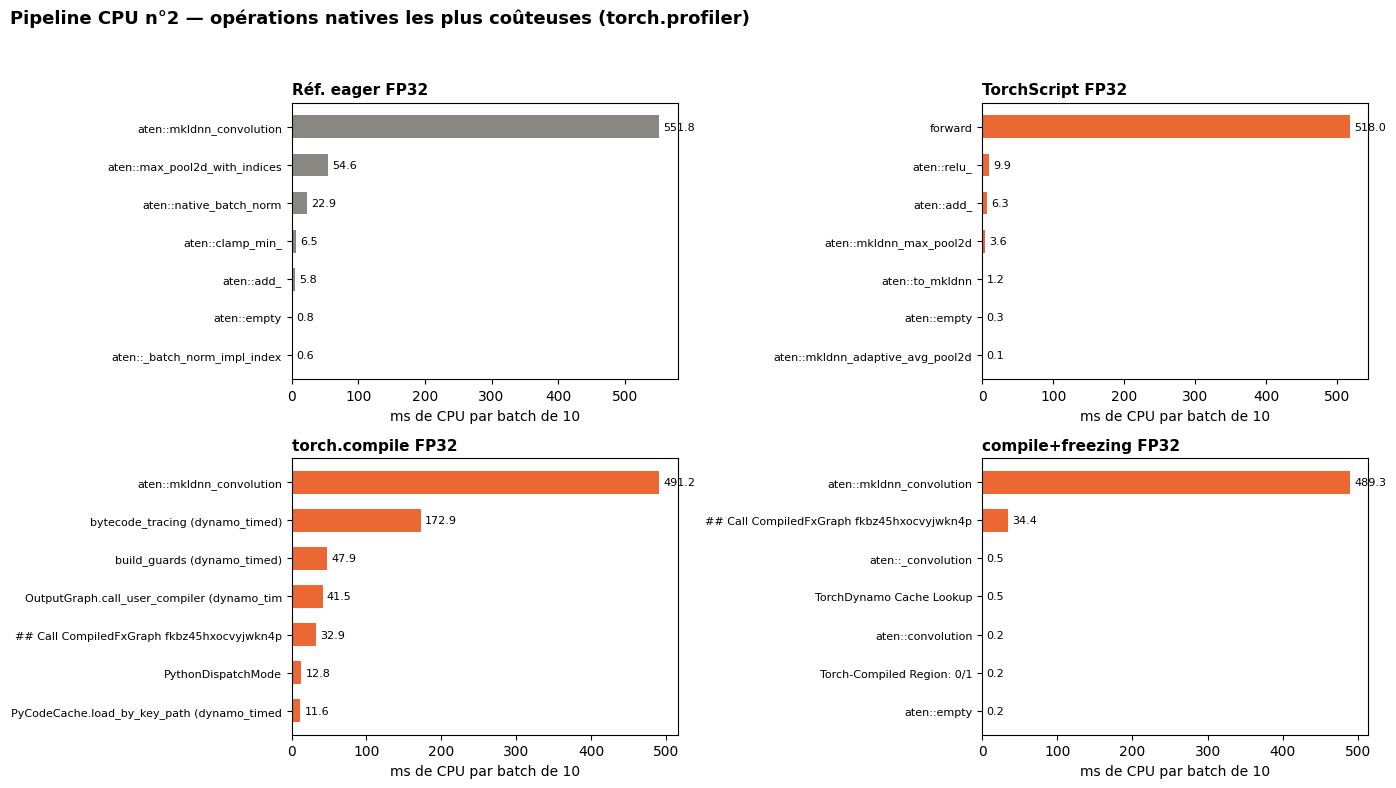


=== Réf. eager FP32 ===


,opération,appels/batch,temps CPU propre (ms/batch)
5,aten::mkldnn_convolution,20.0,551.786
16,aten::max_pool2d_with_indices,1.0,54.611
11,aten::native_batch_norm,20.0,22.853
14,aten::clamp_min_,17.0,6.495
17,aten::add_,8.0,5.813
6,aten::empty,160.0,0.830
10,aten::_batch_norm_impl_index,20.0,0.641
2,aten::conv2d,20.0,0.609
4,aten::_convolution,20.0,0.354
0,aten::slice,1.0,0.239



=== TorchScript FP32 ===


,opération,appels/batch,temps CPU propre (ms/batch)
2,forward,1.0,517.989
5,aten::relu_,17.0,9.881
8,aten::add_,8.0,6.254
7,aten::mkldnn_max_pool2d,1.0,3.624
3,aten::to_mkldnn,1.0,1.228
4,aten::empty,21.0,0.276
10,aten::mkldnn_adaptive_avg_pool2d,1.0,0.103
12,aten::_to_dense,1.0,0.063
18,aten::mm,1.0,0.041
6,aten::max_pool2d,1.0,0.022



=== torch.compile FP32 ===


,opération,appels/batch,temps CPU propre (ms/batch)
67,aten::mkldnn_convolution,20.000,491.227
13,bytecode_tracing (dynamo_timed),0.333,172.857
58,build_guards (dynamo_timed),0.333,47.907
43,OutputGraph.call_user_compiler (dynamo_timed),0.333,41.488
65,## Call CompiledFxGraph fkbz45hxocvyjwkn4pujfu...,1.000,32.854
18,PythonDispatchMode,37.667,12.836
52,PyCodeCache.load_by_key_path (dynamo_timed),0.333,11.640
10,compile_attempt_0 (dynamo_timed),0.333,10.818
40,insert_deferred_runtime_asserts (dynamo_timed),0.333,3.577
14,aten::empty_strided,104.667,1.998



=== compile+freezing FP32 ===


,opération,appels/batch,temps CPU propre (ms/batch)
9,aten::mkldnn_convolution,20.0,489.342
6,## Call CompiledFxGraph fkbz45hxocvyjwkn4pujfu...,1.0,34.449
8,aten::_convolution,20.0,0.473
2,TorchDynamo Cache Lookup,1.0,0.456
7,aten::convolution,20.0,0.221
3,Torch-Compiled Region: 0/1,1.0,0.166
10,aten::empty,20.0,0.152
11,aten::resize_,20.0,0.137
12,aten::addmm,1.0,0.060
4,Pregraph bytecode,1.0,0.032


In [ ]:
from torch.profiler import profile, ProfilerActivity

def profile_ops(fn, n=3):
    with profile(activities=[ProfilerActivity.CPU]) as prof:
        for i in range(n):
            fn(X50[i * BATCH_SIZE:(i + 1) * BATCH_SIZE])
    rows = [{"opération": e.key, "appels/batch": e.count / n, "temps CPU propre (ms/batch)": e.self_cpu_time_total / 1e3 / n}
            for e in prof.key_averages()]
    df = pd.DataFrame(rows).sort_values("temps CPU propre (ms/batch)", ascending=False)
    return df[df["temps CPU propre (ms/batch)"] > 0]

PROFILES = {"Réf. eager FP32": profile_ops(infer_eager), "TorchScript FP32": profile_ops(infer_ts),
            "torch.compile FP32": profile_ops(infer_compile), "compile+freezing FP32": profile_ops(infer_compile_frz)}
summary_ops = pd.DataFrame({k: {"opérations distinctes": len(v), "appels natifs / batch": v["appels/batch"].sum(),
                                "temps profilé (ms/batch)": v["temps CPU propre (ms/batch)"].sum()}
                            for k, v in PROFILES.items()}).T
display(summary_ops.round(1))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (name, df) in zip(axes.ravel(), PROFILES.items()):
    top = df.head(7)[::-1]
    color = "#898781" if "eager" in name else "#eb6834"
    ax.barh([o[:42] for o in top["opération"]], top["temps CPU propre (ms/batch)"], color=color, height=0.6)
    for i, v in enumerate(top["temps CPU propre (ms/batch)"]):
        ax.annotate(f"{v:.1f}", (v, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
    ax.set_title(name, loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("ms de CPU par batch de 10")
    ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Pipeline CPU n°2 — opérations natives les plus coûteuses (torch.profiler)", fontsize=13,
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(f"{FIGS}/pt_profil_operations.png", bbox_inches="tight"); plt.show()
for name, df in PROFILES.items():
    print(f"\n=== {name} ==="); display(df.head(10).round(3))

## 7. Résultats du pipeline PyTorch (vs référence de la même session)
Barres d'erreur : **± 1 écart-type** sur les 10 répétitions (3 pour l'énergie).

In [ ]:
# ============================================================
# Outils de visualisation et de comparaison — IDENTIQUES dans les deux notebooks
# ============================================================
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
# Une couleur par famille de pipeline (même couleur dans tous les graphiques) ;
# les variantes FP16 sont hachurées pour ne pas reposer sur la couleur seule.
FAMILY_COLORS = {"reference": "#898781", "pipeline1": "#2a78d6", "pipeline2": "#eb6834"}
FAMILY_NAMES = {"reference": "Référence : PyTorch eager",
                "pipeline1": "Pipeline n°1 : ONNX → moteur spécialisé (OpenVINO / TensorRT)",
                "pipeline2": "Pipeline n°2 : compilation PyTorch (TorchScript / torch.compile)"}
HATCHES = {"FP16": "///", "INT8": "xx"}

def load_results(keys=None):
    allres = {}
    for p in sorted(glob.glob(f"{RESULTS}/*.json")):
        with open(p) as f:
            r = json.load(f)
        if "key" in r and "summary" in r:
            allres[r["key"]] = r
    if keys is None:
        return allres
    return {k: allres[k] for k in keys if k in allres}

def _stat(r, name, energy=False):
    if energy:
        if not r.get("energy"):
            return None
        return r["energy"]["summary"].get(name)
    return r["summary"].get(name)

def bar_chart(ax, results, name, ylabel, title, energy=False, log=False, fmt="{:.1f}", baseline=None):
    labels, means, stds, colors, hatches = [], [], [], [], []
    for r in results.values():
        s = _stat(r, name, energy)
        if s is None:
            continue
        labels.append(r["label"]); means.append(s["mean"]); stds.append(s["std"])
        colors.append(FAMILY_COLORS.get(r["family"], "#898781"))
        hatches.append(HATCHES.get(r["precision"], ""))
    if not labels:
        ax.text(0.5, 0.5, "Mesure indisponible", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
        return
    x = np.arange(len(labels))
    bars = ax.bar(x, means, yerr=stds, capsize=4, width=0.62, color=colors,
                  edgecolor="white", linewidth=1.5,
                  error_kw={"elinewidth": 1.1, "ecolor": "#0b0b0b", "capthick": 1.1})
    for b, h in zip(bars, hatches):
        b.set_hatch(h)
    for xi, m, s in zip(x, means, stds):
        ax.annotate(fmt.format(m), (xi, m + s), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color="#0b0b0b")
    if baseline is not None:
        ax.axhline(baseline, color="#52514e", linewidth=1, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.grid(axis="x", visible=False)
    if log:
        ax.set_yscale("log")
    else:
        ax.set_ylim(0, max(m + s for m, s in zip(means, stds)) * 1.18)

def add_legend(fig, results):
    fams = []
    for r in results.values():
        if r["family"] not in fams:
            fams.append(r["family"])
    handles = [Patch(facecolor=FAMILY_COLORS[f], label=FAMILY_NAMES[f]) for f in fams]
    for prec, h in HATCHES.items():
        if any(r["precision"] == prec for r in results.values()):
            handles.append(Patch(facecolor="#c3c2b7", hatch=h, edgecolor="white", label=f"Variante {prec}"))
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 4),
               frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=9)

def fig_performance(results, suptitle, fname, log=False):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    bar_chart(axes[0, 0], results, "throughput_img_s", "images / s", "Débit (moyenne ± écart-type)", log=log)
    bar_chart(axes[0, 1], results, "batch_latency_mean_ms", "ms / batch",
              f"Latence par batch de {BATCH_SIZE} images", log=log, fmt="{:.2f}")
    bar_chart(axes[1, 0], results, "total_time_ms", "ms", f"Temps d'inférence total ({N_IMAGES} images)",
              log=log, fmt="{:.1f}")
    bar_chart(axes[1, 1], results, "top1_acc_pct", "%", "Précision Top-1 sur les 50 images", fmt="{:.0f}")
    axes[1, 1].set_ylim(0, 105)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def fig_energy(results, suptitle, fname, log=False):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    bar_chart(axes[0], results, "energy_per_image_mj", "mJ / image", "Énergie par image (brute)",
              energy=True, log=log, fmt="{:.2f}")
    bar_chart(axes[1], results, "net_energy_per_image_mj", "mJ / image",
              "Énergie par image (nette, repos déduit)", energy=True, log=log, fmt="{:.2f}")
    bar_chart(axes[2], results, "mean_power_w", "W", "Puissance moyenne pendant l'inférence",
              energy=True, fmt="{:.1f}")
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def fig_variability(results, suptitle, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
    data, labels, colors = [], [], []
    for r in results.values():
        tp = np.array([run["throughput_img_s"] for run in r["runs"]])
        data.append(100 * tp / np.median(tp))
        labels.append(r["label"]); colors.append(FAMILY_COLORS.get(r["family"], "#898781"))
    bp = axes[0].boxplot(data, patch_artist=True, widths=0.55, showmeans=True, showfliers=False,
                         meanprops={"marker": "D", "markerfacecolor": "#0b0b0b", "markeredgecolor": "white", "markersize": 6},
                         medianprops={"color": "#0b0b0b"})
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c); patch.set_alpha(0.75)
    for i, d in enumerate(data, start=1):
        axes[0].scatter(np.full(len(d), i) + np.random.uniform(-0.12, 0.12, len(d)), d,
                        s=14, color="#0b0b0b", alpha=0.6, zorder=3)
    axes[0].axhline(100, color="#52514e", linewidth=1, linestyle="--")
    axes[0].set_xticks(range(1, len(labels) + 1))
    axes[0].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[0].set_ylabel("% de la médiane")
    axes[0].set_title("Dispersion du débit entre répétitions (normalisé)", loc="left", fontsize=11, fontweight="bold")
    axes[0].grid(axis="x", visible=False)
    cv =[r["summary"]["throughput_img_s"]["cv_pct"] for r in results.values()]
    x = np.arange(len(cv))
    axes[1].bar(x, cv, width=0.62, color=colors, edgecolor="white", linewidth=1.5)
    for xi, v in zip(x, cv):
        axes[1].annotate(f"{v:.1f} %", (xi, v), xytext=(0, 3), textcoords="offset points",
                         ha="center", fontsize=8)
    axes[1].axhline(5, color="#52514e", linewidth=1, linestyle="--")
    axes[1].text(len(cv) - 0.5, 5, " seuil 5 %", va="bottom", ha="right", fontsize=8, color="#52514e")
    axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[1].set_ylabel("CV = écart-type / moyenne (%)")
    axes[1].set_title("Coefficient de variation du débit", loc="left", fontsize=11, fontweight="bold")
    axes[1].grid(axis="x", visible=False)
    axes[1].set_ylim(0, max(max(cv) * 1.25, 6))
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def _softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def prediction_comparison(results, ref_key):
    logits = {k: np.load(f"{RESULTS}/{k}_logits.npy") for k in results}
    keys = list(logits)
    preds = {k: v.argmax(1) for k, v in logits.items()}
    M = np.array([[100 * (preds[a] == preds[b]).mean() for b in keys] for a in keys])
    ref = logits[ref_key]
    pref = _softmax(ref)
    rows = []
    for k, v in logits.items():
        rows.append({"pipeline": results[k]["label"],
                     "accord_top1_vs_ref_%": 100 * (preds[k] == preds[ref_key]).mean(),
                     "max_|Δlogit|": float(np.abs(v - ref).max()),
                     "moy_|Δlogit|": float(np.abs(v - ref).mean()),
                     "max_|Δproba|": float(np.abs(_softmax(v) - pref).max()),
                     "top1_%": 100 * (preds[k] == Y50_NP).mean()})
    return keys, M, pd.DataFrame(rows).set_index("pipeline")

def fig_agreement(results, ref_key, suptitle, fname):
    keys, M, df = prediction_comparison(results, ref_key)
    labels = [results[k]["label"] for k in keys]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
    vmin = min(90, M.min())
    im = axes[0].imshow(M, cmap="Blues", vmin=vmin, vmax=100)
    for i in range(len(keys)):
        for j in range(len(keys)):
            axes[0].text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=8,
                         color="white" if M[i, j] > (vmin + 100) / 2 else "#0b0b0b")
    axes[0].set_xticks(range(len(keys))); axes[0].set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    axes[0].set_yticks(range(len(keys))); axes[0].set_yticklabels(labels, fontsize=8)
    axes[0].grid(False)
    axes[0].set_title("Accord des prédictions Top-1 entre pipelines (%)", loc="left", fontsize=11, fontweight="bold")
    fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
    d = df["max_|Δlogit|"].values
    colors = [FAMILY_COLORS.get(results[k]["family"], "#898781") for k in keys]
    x = np.arange(len(keys))
    axes[1].bar(x, np.maximum(d, 1e-8), width=0.62, color=colors, edgecolor="white", linewidth=1.5)
    for xi, v in zip(x, d):
        axes[1].annotate(f"{v:.1e}", (xi, max(v, 1e-8)), xytext=(0, 3), textcoords="offset points",
                         ha="center", fontsize=8)
    axes[1].set_yscale("log")
    axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[1].set_ylabel("max |logit − logit_réf| (échelle log)")
    axes[1].set_title(f"Écart numérique vs {results[ref_key]['label']}", loc="left", fontsize=11, fontweight="bold")
    axes[1].grid(axis="x", visible=False)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()
    return df

def summary_table(results):
    rows = []
    for r in results.values():
        s = r["summary"]; e = r["energy"]["summary"] if r.get("energy") else None
        row = {
            "pipeline": r["label"], "plateforme": r["platform"], "précision": r["precision"],
            "débit moy (img/s)": s["throughput_img_s"]["mean"], "débit σ": s["throughput_img_s"]["std"],
            "débit min": s["throughput_img_s"]["min"], "débit max": s["throughput_img_s"]["max"],
            "débit CV %": s["throughput_img_s"]["cv_pct"],
            "latence batch moy (ms)": s["batch_latency_mean_ms"]["mean"], "latence σ": s["batch_latency_mean_ms"]["std"],
            "latence min": s["batch_latency_mean_ms"]["min"], "latence max": s["batch_latency_mean_ms"]["max"],
            "temps 50 img moy (ms)": s["total_time_ms"]["mean"], "temps σ": s["total_time_ms"]["std"],
            "temps min": s["total_time_ms"]["min"], "temps max": s["total_time_ms"]["max"],
            "Top-1 moy %": s["top1_acc_pct"]["mean"], "Top-1 σ": s["top1_acc_pct"]["std"],
        }
        if e:
            row.update({"E/image moy (mJ)": e["energy_per_image_mj"]["mean"], "E/image σ": e["energy_per_image_mj"]["std"],
                        "E nette/image (mJ)": e["net_energy_per_image_mj"]["mean"],
                        "puissance moy (W)": e["mean_power_w"]["mean"], "méthode énergie": r["energy"]["method"]})
        rows.append(row)
    return pd.DataFrame(rows).set_index("pipeline")

def auto_comments(results, ref_key):
    # Génère des constats chiffrés pour aider à rédiger l'analyse (à reformuler dans le rapport).
    ref = results[ref_key]
    tref = ref["summary"]["throughput_img_s"]["mean"]
    print(f"Référence : {ref['label']} = {tref:.1f} img/s\n")
    best = max(results.values(), key=lambda r: r["summary"]["throughput_img_s"]["mean"])
    for r in results.values():
        s = r["summary"]
        tp = s["throughput_img_s"]
        line = (f"- {r['label']:<28} débit {tp['mean']:9.1f} img/s  (×{tp['mean'] / tref:5.2f} vs réf.)"
                f"  CV {tp['cv_pct']:4.1f} %  [{tp['min']:.1f} ; {tp['max']:.1f}]"
                f"  Top-1 {s['top1_acc_pct']['mean']:.0f} %")
        if r.get("energy"):
            line += f"  E/img {r['energy']['summary']['energy_per_image_mj']['mean']:.2f} mJ"
        stab = "stable" if tp["cv_pct"] < 2 else ("assez stable" if tp["cv_pct"] < 5 else "VARIABLE")
        print(line + f"  → {stab}")
    print(f"\nPipeline le plus rapide : {best['label']}")
    accs = {r["label"]: r["summary"]["top1_acc_pct"]["mean"] for r in results.values()}
    if max(accs.values()) - min(accs.values()) == 0:
        print("Précision Top-1 identique pour tous les pipelines : les optimisations ne dégradent pas les prédictions.")
    else:
        print("Écarts de précision Top-1 observés :", {k: f"{v:.0f} %" for k, v in accs.items()})

def session_ref(r):
    k = r.get("session_ref_key") or ("gpu0_eager_fp32" if r["platform"] == "GPU" else None)
    p = f"{RESULTS}/{k}.json" if k else None
    if p and os.path.exists(p):
        with open(p) as f:
            return json.load(f)
    return None

def fig_speedup(results, suptitle, fname):
    # Accélération du débit par rapport à la référence eager de LA MÊME SESSION (même machine) :
    # robuste au fait que chaque notebook Colab tourne sur sa propre machine virtuelle.
    labs, sp, err, cols, hat = [], [], [], [], []
    for r in results.values():
        ref = session_ref(r)
        if ref is None:
            continue
        a, b = r["summary"]["throughput_img_s"], ref["summary"]["throughput_img_s"]
        v = a["mean"] / b["mean"]
        labs.append(r["label"]); sp.append(v)
        err.append(v * np.sqrt((a["std"] / a["mean"]) ** 2 + (b["std"] / b["mean"]) ** 2))
        cols.append(FAMILY_COLORS.get(r["family"], "#898781")); hat.append(HATCHES.get(r["precision"], ""))
    fig, ax = plt.subplots(figsize=(max(8, 1.25 * len(labs) + 3), 4.8))
    bars = ax.bar(range(len(sp)), sp, yerr=err, capsize=4, color=cols, edgecolor="white", linewidth=1.5, width=0.62,
                  error_kw={"elinewidth": 1.1, "ecolor": "#0b0b0b"})
    for b_, h in zip(bars, hat):
        b_.set_hatch(h)
    for i, v in enumerate(sp):
        ax.annotate(f"×{v:.2f}", (i, v + err[i]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
    ax.axhline(1, color="#52514e", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, rotation=28, ha="right", fontsize=8)
    ax.set_ylabel("débit / débit eager de la même session")
    ax.set_title("Accélération par rapport à PyTorch eager FP32 (même machine)", loc="left", fontsize=11, fontweight="bold")
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, max(v + e for v, e in zip(sp, err)) * 1.18 if sp else 1)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.08, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def history_table():
    # Une ligne par (pipeline, session) : chaque exécution complète d'un notebook = une exécution indépendante.
    rows = []
    for p in sorted(glob.glob(f"{RESULTS}/history/*.json")):
        with open(p) as f:
            r = json.load(f)
        s = r["summary"]
        rows.append({"pipeline": r["label"], "session": r.get("session_id"), "cpu": r["env"].get("cpu"),
                     "débit (img/s)": s["throughput_img_s"]["mean"],
                     "latence batch (ms)": s["batch_latency_mean_ms"]["mean"],
                     "Top-1 %": s["top1_acc_pct"]["mean"]})
    df = pd.DataFrame(rows)
    if df.empty:
        return df, df
    agg = df.groupby("pipeline").agg(
        sessions=("session", "nunique"),
        débit_moy=("débit (img/s)", "mean"), débit_σ_inter_sessions=("débit (img/s)", "std"),
        débit_min=("débit (img/s)", "min"), débit_max=("débit (img/s)", "max"),
        latence_moy=("latence batch (ms)", "mean"), latence_σ_inter_sessions=("latence batch (ms)", "std"),
        top1_moy=("Top-1 %", "mean"))
    agg["débit_CV_inter_%"] = 100 * agg["débit_σ_inter_sessions"] / agg["débit_moy"]
    return df, agg

print("Outils de visualisation prêts.")

Outils de visualisation prêts.


In [ ]:
PT_KEYS = ["cpu_pt_ref_eager", "cpu2_torchscript_fp32", "cpu2_compile_fp32",
           "cpu2_compile_freezing_fp32", "cpu2_compile_autotune_fp32"]
pt_results = load_results(PT_KEYS)
df_pt = summary_table(pt_results)
df_pt.to_csv(f"{RESULTS}/summary_pipeline_pytorch.csv")
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 40)
df_pt

,plateforme,précision,débit moy (img/s),débit σ,débit min,débit max,débit CV %,latence batch moy (ms),latence σ,latence min,latence max,temps 50 img moy (ms),temps σ,temps min,temps max,Top-1 moy %,Top-1 σ,E/image moy (mJ),E/image σ,E nette/image (mJ),puissance moy (W),méthode énergie
pipeline,,,,,,,,,,,,,,,,,,,,,,
Réf. eager FP32 (session PT),CPU,FP32,12.59,2.69,8.39,14.78,21.37,833.77,208.12,676.61,1192.25,4168.86,1040.61,3383.08,5961.26,90.0,0.0,1622.67,128.77,1622.67,19.90,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-2 TorchScript FP32,CPU,FP32,15.74,3.69,10.28,18.81,23.47,674.10,185.28,531.58,972.45,3370.53,926.39,2657.90,4862.26,90.0,0.0,1316.39,115.97,1316.39,19.96,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-2 torch.compile FP32,CPU,FP32,16.62,3.17,10.98,19.15,19.05,625.59,140.60,522.30,910.82,3127.95,703.02,2611.52,4554.10,90.0,0.0,1219.83,84.56,1219.83,19.95,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-2 compile+freezing FP32,CPU,FP32,18.60,3.34,11.40,20.58,17.96,559.74,136.79,485.86,876.90,2798.73,683.95,2429.31,4384.53,90.0,0.0,1195.50,3.50,1195.50,19.96,Estimation : 10 W par vCPU actif × temps CPU a...


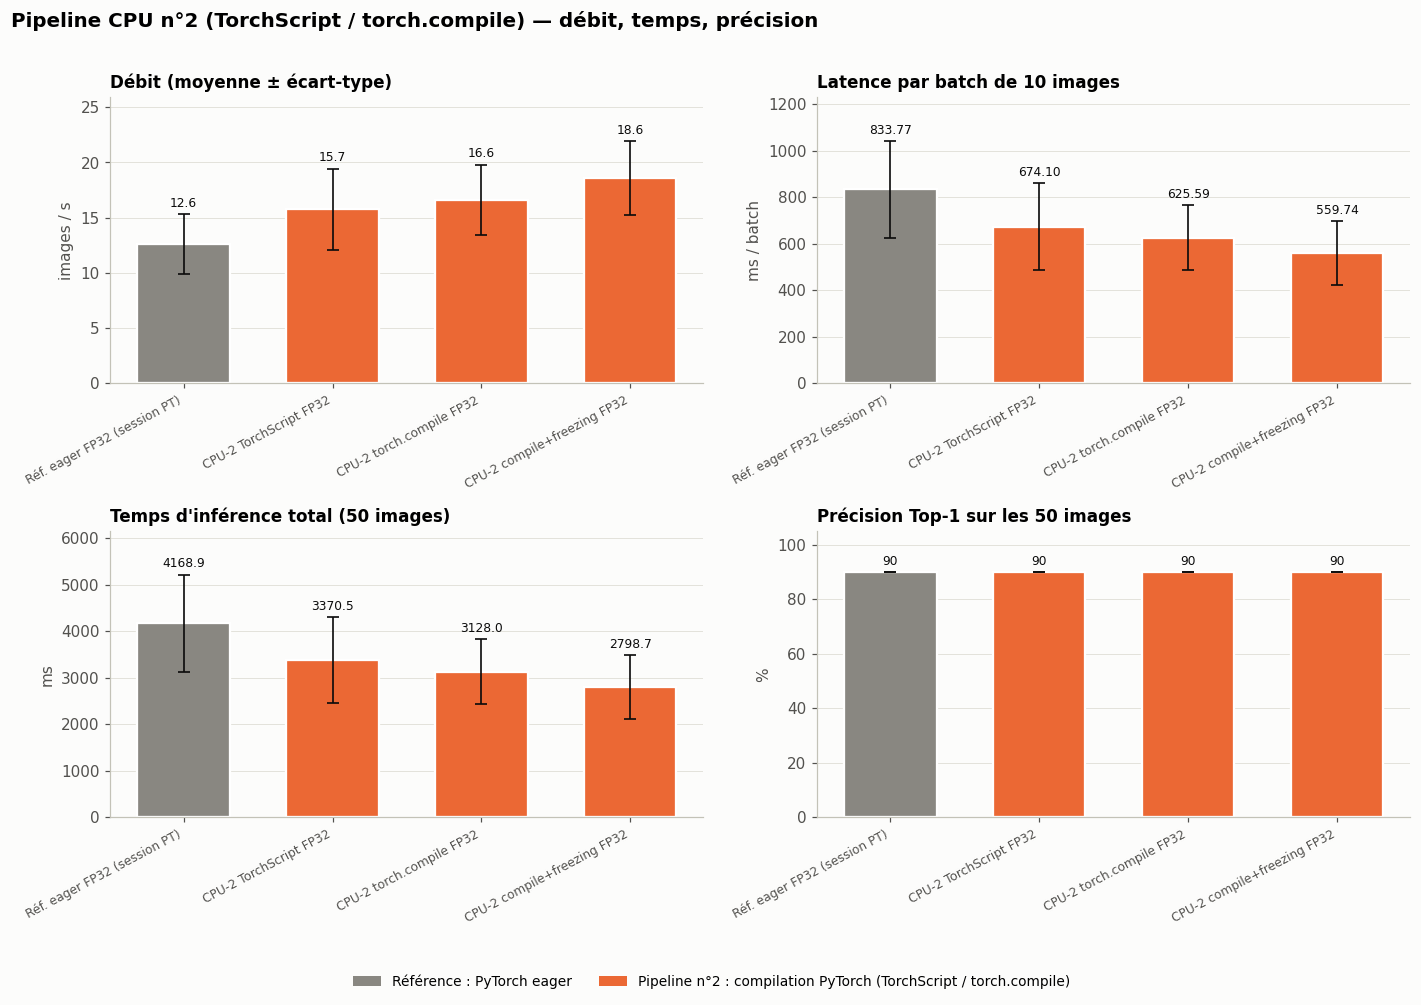

In [ ]:
fig_performance(pt_results, "Pipeline CPU n°2 (TorchScript / torch.compile) — débit, temps, précision", "pt_performance.png")

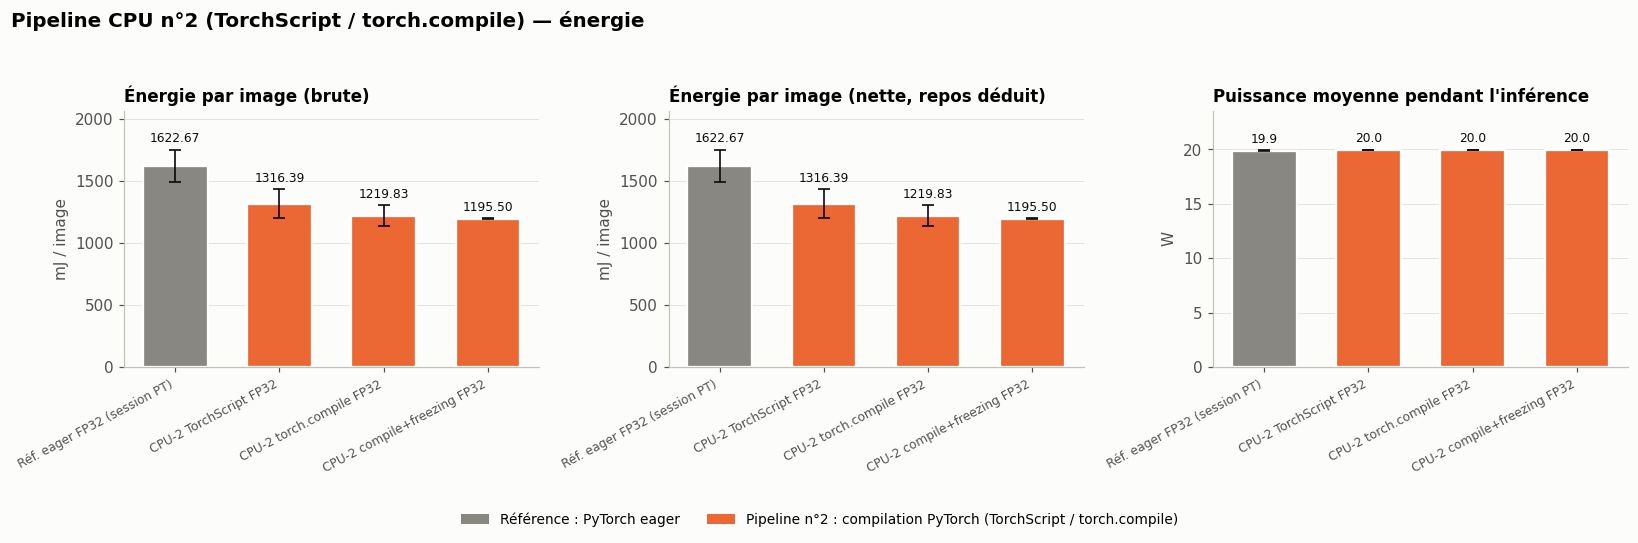

In [ ]:
fig_energy(pt_results, "Pipeline CPU n°2 (TorchScript / torch.compile) — énergie", "pt_energie.png")

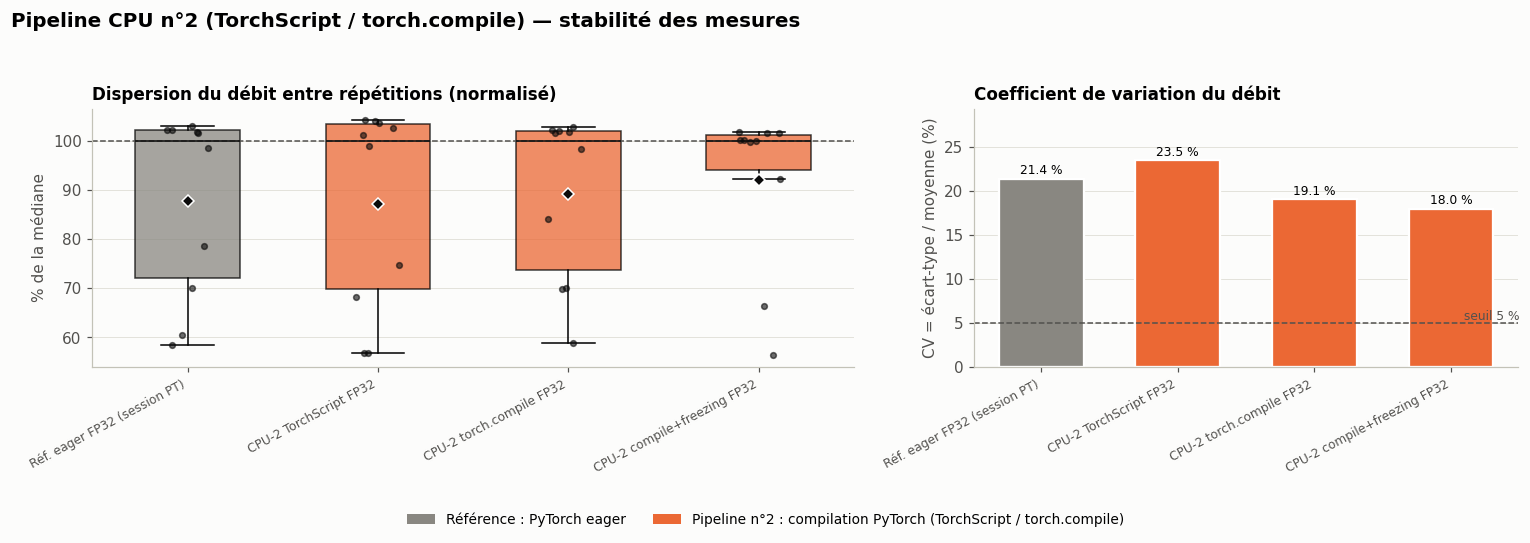

In [ ]:
fig_variability(pt_results, "Pipeline CPU n°2 (TorchScript / torch.compile) — stabilité des mesures", "pt_variabilite.png")

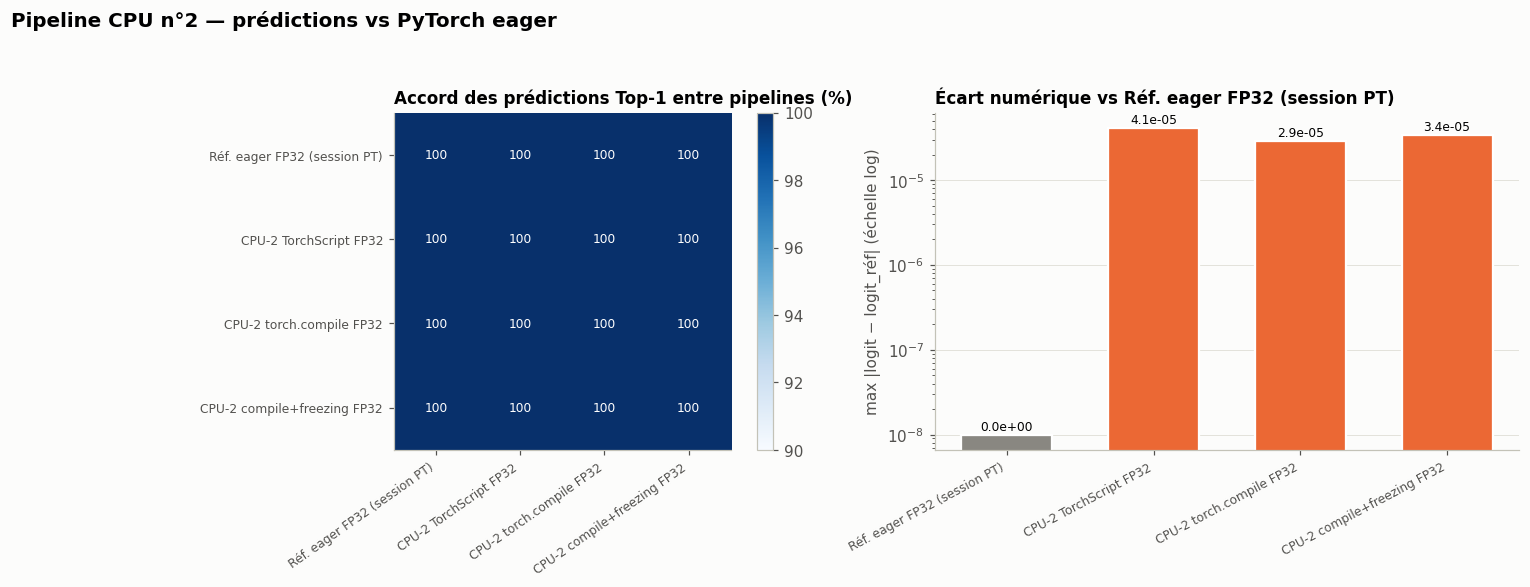

,accord_top1_vs_ref_%,max_|Δlogit|,moy_|Δlogit|,max_|Δproba|,top1_%
pipeline,,,,,
Réf. eager FP32 (session PT),100.0,0.00e+00,0.00e+00,0.00e+00,90.0
CPU-2 TorchScript FP32,100.0,4.10e-05,9.23e-06,5.48e-06,90.0
CPU-2 torch.compile FP32,100.0,2.86e-05,5.72e-06,5.07e-06,90.0
CPU-2 compile+freezing FP32,100.0,3.43e-05,7.41e-06,4.53e-06,90.0


In [ ]:
df_agree_pt = fig_agreement(pt_results, "cpu_pt_ref_eager", "Pipeline CPU n°2 — prédictions vs PyTorch eager",
                            "pt_predictions.png")
df_agree_pt

In [ ]:
auto_comments(pt_results, "cpu_pt_ref_eager")
for r in pt_results.values():
    x = r.get("extra", {})
    if "compile_time_s" in x or "prep_time_s" in x:
        t = x.get("compile_time_s", x.get("prep_time_s"))
        gain_ms = (pt_results["cpu_pt_ref_eager"]["summary"]["per_image_time_ms"]["mean"]
                   - r["summary"]["per_image_time_ms"]["mean"])
        amort = f"amortie après ≈ {t * 1e3 / gain_ms:,.0f} images" if gain_ms > 0 else "jamais amortie (pas de gain)"
        print(f"{r['label']}: préparation/compilation {t:.1f} s → {amort}")

Référence : Réf. eager FP32 (session PT) = 12.6 img/s

- Réf. eager FP32 (session PT) débit      12.6 img/s  (× 1.00 vs réf.)  CV 21.4 %  [8.4 ; 14.8]  Top-1 90 %  E/img 1622.67 mJ  → VARIABLE
- CPU-2 TorchScript FP32       débit      15.7 img/s  (× 1.25 vs réf.)  CV 23.5 %  [10.3 ; 18.8]  Top-1 90 %  E/img 1316.39 mJ  → VARIABLE
- CPU-2 torch.compile FP32     débit      16.6 img/s  (× 1.32 vs réf.)  CV 19.1 %  [11.0 ; 19.1]  Top-1 90 %  E/img 1219.83 mJ  → VARIABLE
- CPU-2 compile+freezing FP32  débit      18.6 img/s  (× 1.48 vs réf.)  CV 18.0 %  [11.4 ; 20.6]  Top-1 90 %  E/img 1195.50 mJ  → VARIABLE

Pipeline le plus rapide : CPU-2 compile+freezing FP32
Précision Top-1 identique pour tous les pipelines : les optimisations ne dégradent pas les prédictions.
CPU-2 TorchScript FP32: préparation/compilation 7.2 s → amortie après ≈ 448 images
CPU-2 torch.compile FP32: préparation/compilation 34.9 s → amortie après ≈ 1,676 images
CPU-2 compile+freezing FP32: préparation/compilation 9.2 s →

## 8. Comparaison des pipelines (section identique dans les deux notebooks)

Cette section recharge **tous les résultats présents dans le dossier `results`** : ceux de ce notebook, ceux de l'autre notebook CPU s'il a déjà été exécuté, et ceux des pipelines GPU s'ils ont été produits au même format (notebook GPU). **Exécutez-la à la fin du second notebook** pour obtenir la comparaison complète ; elle fonctionne aussi avec un seul pipeline disponible.

Chaque notebook Colab tourne sur **sa propre machine virtuelle** : on vérifie donc que le modèle de CPU est le même, et on présente l'**accélération par rapport à la référence eager mesurée dans la même session** (comparaison robuste même si les machines diffèrent un peu).

In [ ]:
CPU_KEYS = ["cpu_ov_ref_eager", "cpu1_openvino_fp32", "cpu1_openvino_int8",
            "cpu_pt_ref_eager", "cpu2_torchscript_fp32", "cpu2_compile_fp32", "cpu2_compile_freezing_fp32",
            "cpu2_compile_autotune_fp32"]
GPU_KEYS = ["gpu0_eager_fp32", "gpu1_trt_fp32", "gpu1_trt_fp16", "gpu2_torchscript_fp32",
            "gpu2_compile_fp32", "gpu2_compile_fp16", "gpu2_compile_autotune_fp32"]
REF_KEYS = ["cpu_ov_ref_eager", "cpu_pt_ref_eager", "gpu0_eager_fp32"]

all_results = load_results(CPU_KEYS + GPU_KEYS)
cpu_all = {k: v for k, v in all_results.items() if v["platform"] == "CPU"}
has_gpu = any(v["platform"] == "GPU" for v in all_results.values())
REF_KEY = next(k for k in REF_KEYS if k in all_results)

if "cpu1_openvino_fp32" not in all_results:
    print("ℹ Pipeline CPU n°1 (OpenVINO) pas encore exécuté : lancez son notebook puis relancez cette section.")
if "cpu2_compile_fp32" not in all_results:
    print("ℹ Pipeline CPU n°2 (PyTorch) pas encore exécuté : lancez son notebook puis relancez cette section.")

cond = pd.DataFrame([{"pipeline": r["label"], "session": r.get("session_id"), "images": r["n_images"],
                      "batch": r["batch_size"], "warm-up": r["n_warmup"], "répétitions": r["n_runs"],
                      "SHA-256 entrées": r["test_sha256"][:12], "processeur": r["env"].get("cpu"),
                      "vCPU": r["env"].get("n_vcpu"), "GPU": r["env"].get("gpu", "—")}
                     for r in all_results.values()]).set_index("pipeline")
assert cond["SHA-256 entrées"].nunique() == 1, "Les pipelines n'ont pas utilisé les mêmes images !"
assert cond["batch"].nunique() == 1 and cond["images"].nunique() == 1, "Batch ou nombre d'images différent !"
print("✔ Mêmes 50 images, même prétraitement, même batch pour tous les pipelines.")
cpu_models = {r["env"].get("cpu") for r in cpu_all.values()}
if len(cpu_models) > 1:
    print("⚠ Les sessions CPU n'ont pas eu le même processeur :", cpu_models,
          "\n  → comparez surtout l'accélération vs eager de la même session, ou relancez pour obtenir le même CPU.")
cond

✔ Mêmes 50 images, même prétraitement, même batch pour tous les pipelines.


,session,images,batch,warm-up,répétitions,SHA-256 entrées,processeur,vCPU,GPU
pipeline,,,,,,,,,
Réf. eager FP32 (session OV),ov_20261116-085931,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.20GHz,2,—
CPU-1 OpenVINO FP32,ov_20261116-085931,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.20GHz,2,—
CPU-1 OpenVINO INT8,ov_20261116-085931,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.20GHz,2,—
Réf. eager FP32 (session PT),pt_20261116-104050,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.20GHz,2,—
CPU-2 TorchScript FP32,pt_20261116-104050,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.20GHz,2,—
CPU-2 torch.compile FP32,pt_20261116-104050,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.20GHz,2,—
CPU-2 compile+freezing FP32,pt_20261116-104050,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.20GHz,2,—


In [ ]:
df_all = summary_table(all_results)
df_all.to_csv(f"{RESULTS}/summary_all.csv")
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 40)
df_all

,plateforme,précision,débit moy (img/s),débit σ,débit min,débit max,débit CV %,latence batch moy (ms),latence σ,latence min,latence max,temps 50 img moy (ms),temps σ,temps min,temps max,Top-1 moy %,Top-1 σ,E/image moy (mJ),E/image σ,E nette/image (mJ),puissance moy (W),méthode énergie
pipeline,,,,,,,,,,,,,,,,,,,,,,
Réf. eager FP32 (session OV),CPU,FP32,10.97,2.30,7.23,13.07,21.02,954.73,228.97,765.09,1383.26,4773.69,1144.87,3825.47,6916.34,90.0,0.0,1895.78,69.71,1895.78,19.70,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-1 OpenVINO FP32,CPU,FP32,13.63,2.33,10.27,16.11,17.12,754.95,139.99,620.78,973.53,3774.79,699.97,3103.91,4867.67,90.0,0.0,1038.89,277.17,1038.89,13.59,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-1 OpenVINO INT8,CPU,INT8,27.63,4.21,19.76,31.49,15.24,370.87,65.77,317.53,506.06,1854.36,328.86,1587.65,2530.30,92.0,0.0,558.19,102.03,558.19,14.36,Estimation : 10 W par vCPU actif × temps CPU a...
Réf. eager FP32 (session PT),CPU,FP32,12.59,2.69,8.39,14.78,21.37,833.77,208.12,676.61,1192.25,4168.86,1040.61,3383.08,5961.26,90.0,0.0,1622.67,128.77,1622.67,19.90,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-2 TorchScript FP32,CPU,FP32,15.74,3.69,10.28,18.81,23.47,674.10,185.28,531.58,972.45,3370.53,926.39,2657.90,4862.26,90.0,0.0,1316.39,115.97,1316.39,19.96,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-2 torch.compile FP32,CPU,FP32,16.62,3.17,10.98,19.15,19.05,625.59,140.60,522.30,910.82,3127.95,703.02,2611.52,4554.10,90.0,0.0,1219.83,84.56,1219.83,19.95,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-2 compile+freezing FP32,CPU,FP32,18.60,3.34,11.40,20.58,17.96,559.74,136.79,485.86,876.90,2798.73,683.95,2429.31,4384.53,90.0,0.0,1195.50,3.50,1195.50,19.96,Estimation : 10 W par vCPU actif × temps CPU a...


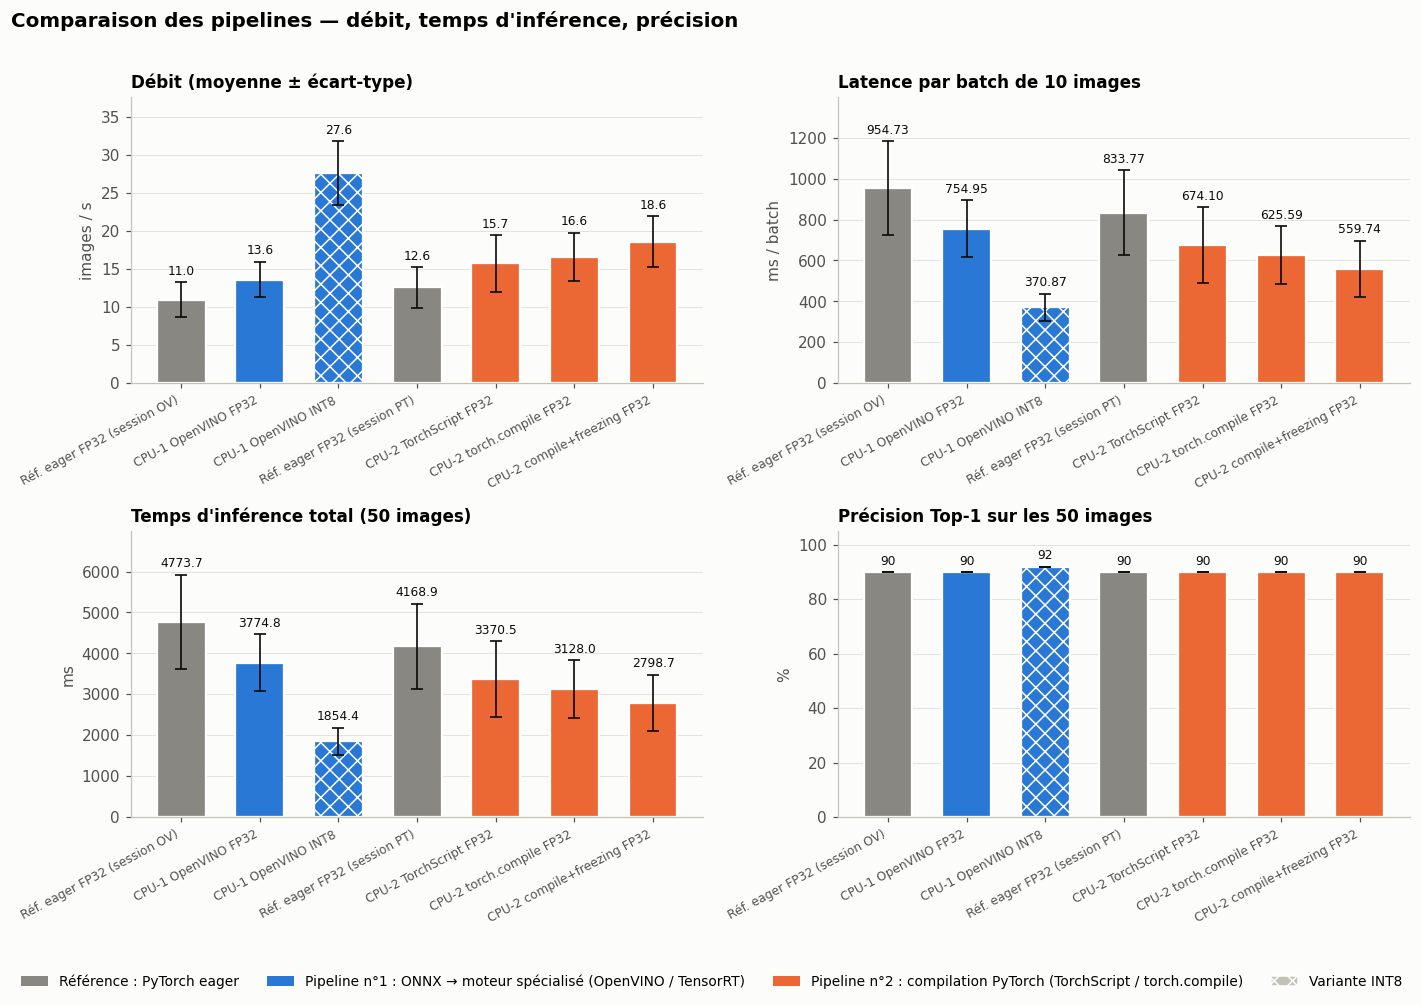

In [ ]:
fig_performance(all_results, "Comparaison des pipelines — débit, temps d'inférence, précision",
                "compare_performance.png", log=has_gpu)

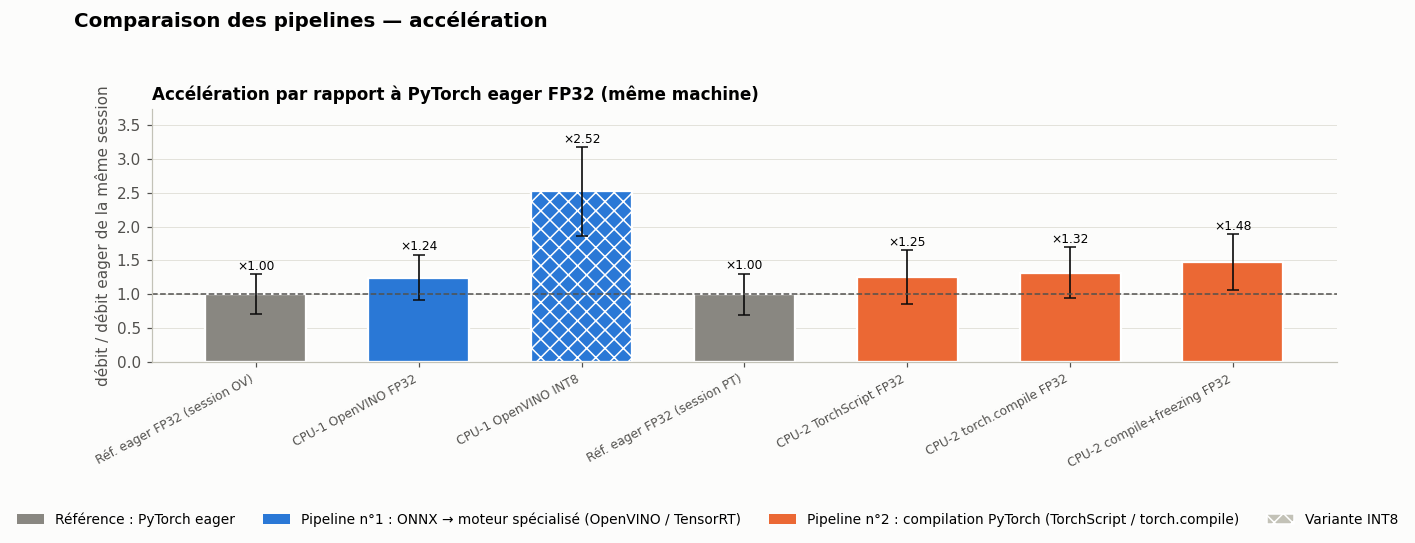

In [ ]:
fig_speedup(all_results, "Comparaison des pipelines — accélération", "compare_acceleration.png")

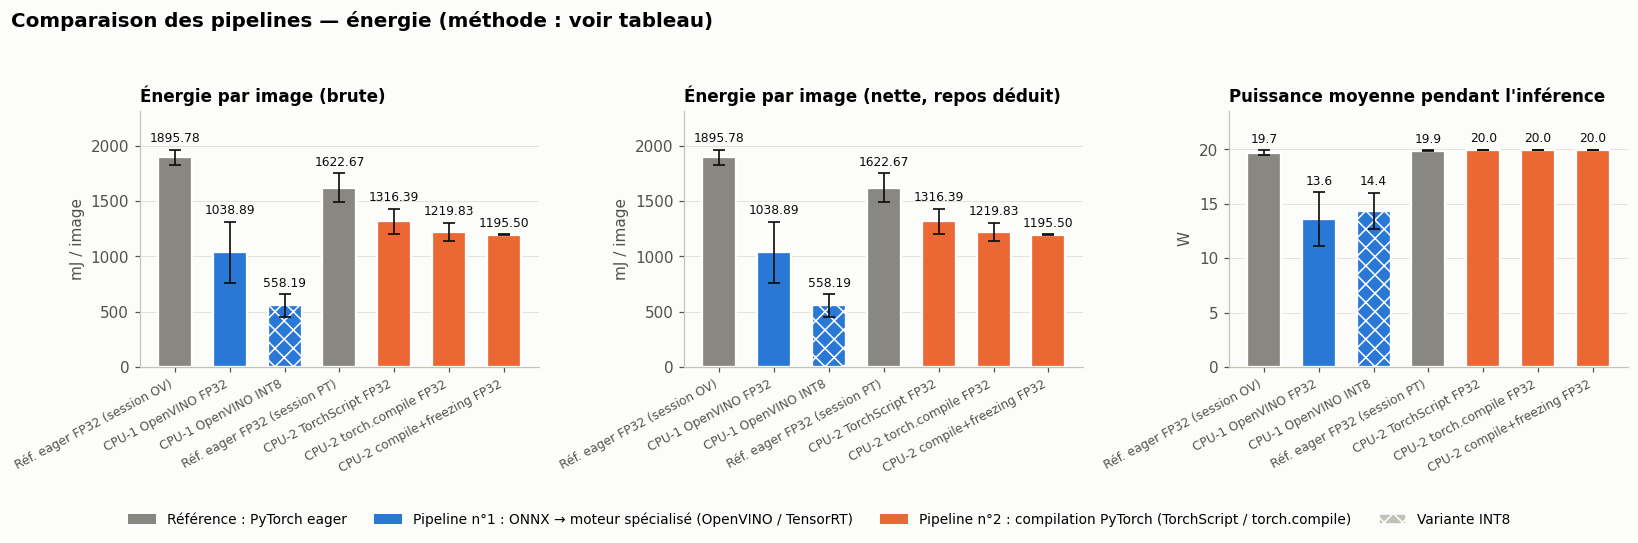

In [ ]:
fig_energy(all_results, "Comparaison des pipelines — énergie (méthode : voir tableau)", "compare_energie.png", log=has_gpu)

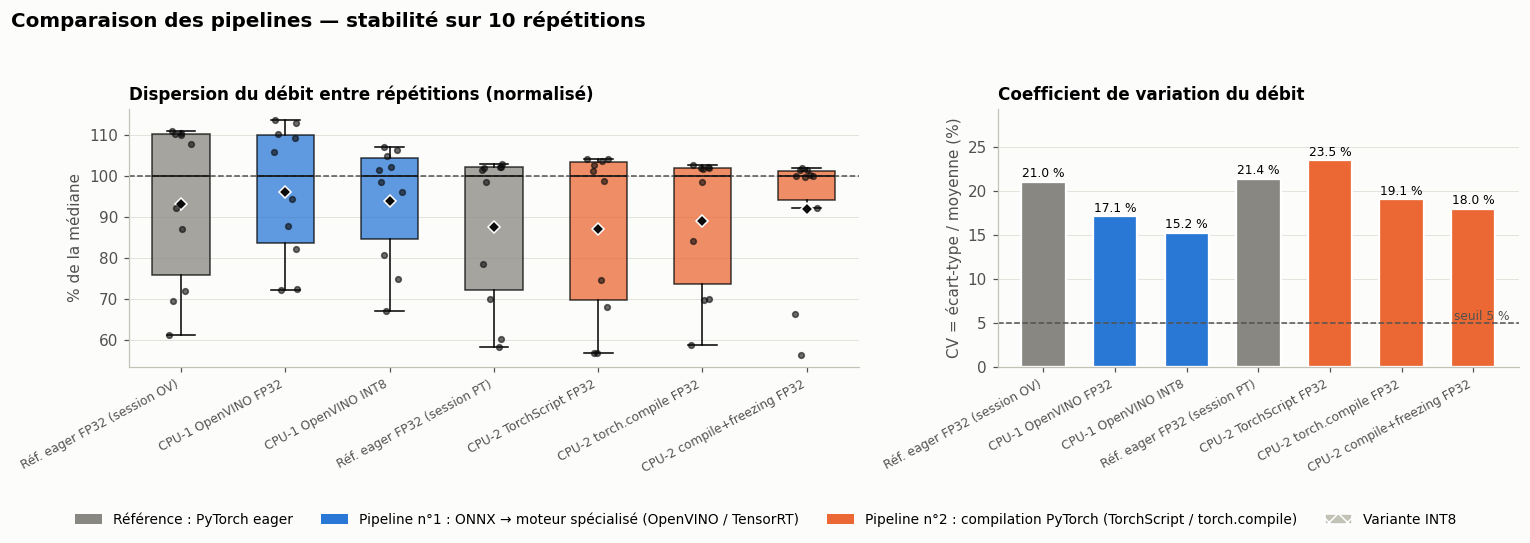

In [ ]:
fig_variability(all_results, "Comparaison des pipelines — stabilité sur 10 répétitions", "compare_variabilite.png")

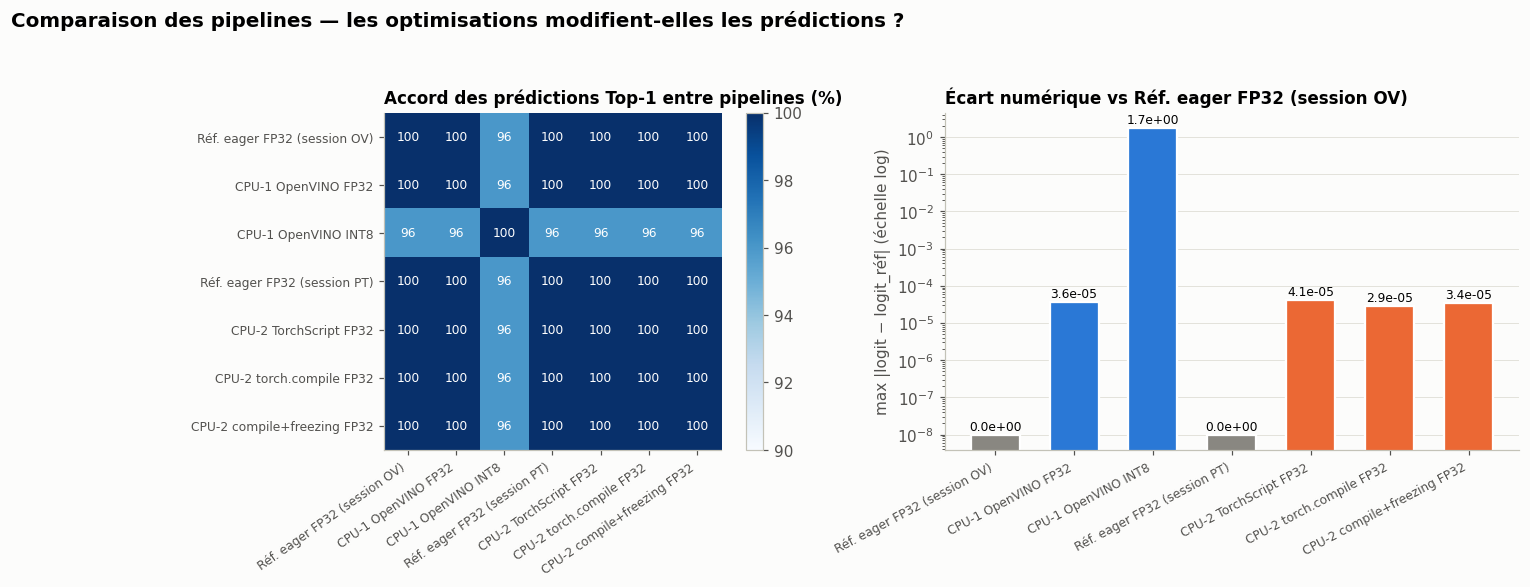

,accord_top1_vs_ref_%,max_|Δlogit|,moy_|Δlogit|,max_|Δproba|,top1_%
pipeline,,,,,
Réf. eager FP32 (session OV),100.0,0.00e+00,0.00e+00,0.00e+00,90.0
CPU-1 OpenVINO FP32,100.0,3.58e-05,7.06e-06,7.09e-06,90.0
CPU-1 OpenVINO INT8,96.0,1.74e+00,3.77e-01,3.17e-01,92.0
Réf. eager FP32 (session PT),100.0,0.00e+00,0.00e+00,0.00e+00,90.0
CPU-2 TorchScript FP32,100.0,4.10e-05,9.23e-06,5.48e-06,90.0
CPU-2 torch.compile FP32,100.0,2.86e-05,5.72e-06,5.07e-06,90.0
CPU-2 compile+freezing FP32,100.0,3.43e-05,7.41e-06,4.53e-06,90.0


In [ ]:
df_agree = fig_agreement(all_results, REF_KEY, "Comparaison des pipelines — les optimisations modifient-elles les prédictions ?",
                         "compare_predictions.png")
df_agree

In [ ]:
# Images dont la prédiction diffère entre pipelines
logits_all = {k: np.load(f"{RESULTS}/{k}_logits.npy") for k in all_results}
ref_pred = logits_all[REF_KEY].argmax(1)
diff_idx = sorted({int(i) for v in logits_all.values() for i in np.where(v.argmax(1) != ref_pred)[0]})
if not diff_idx:
    print("Aucune image ne change de classe prédite : tous les pipelines donnent les mêmes 50 prédictions.")
else:
    rows = []
    for i in diff_idx:
        row = {"image": i, "vraie classe": CLASSES[Y50_NP[i]]}
        row.update({all_results[k]["label"]: CLASSES[int(v[i].argmax())] for k, v in logits_all.items()})
        rows.append(row)
    display(pd.DataFrame(rows).set_index("image"))

,vraie classe,Réf. eager FP32 (session OV),CPU-1 OpenVINO FP32,CPU-1 OpenVINO INT8,Réf. eager FP32 (session PT),CPU-2 TorchScript FP32,CPU-2 torch.compile FP32,CPU-2 compile+freezing FP32
image,,,,,,,,
6,deer,bird,bird,deer,bird,bird,bird,bird
40,deer,bird,bird,horse,bird,bird,bird,bird


### Exécutions indépendantes (variabilité entre sessions)
Les 10 répétitions d'un même notebook ont lieu dans **une même session** (même machine, même processus). Pour mesurer la reproductibilité **entre exécutions indépendantes**, relancez chaque notebook dans une **nouvelle session** (`Exécution` → `Déconnecter et supprimer l'environnement d'exécution`, puis `Tout exécuter`) au moins **3 fois**. Chaque exécution ajoute une ligne par pipeline dans `results/history/`, et le tableau ci-dessous calcule moyenne, écart-type, min et max **entre sessions**.

In [ ]:
hist_rows, hist_agg = history_table()
if hist_rows.empty:
    print("Aucun historique.")
else:
    display(hist_rows)
    display(hist_agg)
    hist_agg.to_csv(f"{RESULTS}/summary_inter_sessions.csv")
    multi = hist_agg[hist_agg["sessions"] >= 2]
    if len(multi):
        fig, ax = plt.subplots(figsize=(11, 4.5))
        for i, (lab, g) in enumerate(hist_rows.groupby("pipeline")):
            ax.scatter(np.full(len(g), i), g["débit (img/s)"], s=30, color="#2a78d6", zorder=3)
            ax.errorbar(i, g["débit (img/s)"].mean(), yerr=g["débit (img/s)"].std() if len(g) > 1 else 0,
                        fmt="D", color="#0b0b0b", capsize=5)
        ax.set_xticks(range(hist_rows["pipeline"].nunique()))
        ax.set_xticklabels(sorted(hist_rows["pipeline"].unique()), rotation=28, ha="right", fontsize=8)
        ax.set_ylabel("débit moyen de la session (img/s)")
        ax.set_title("Débit par session (points) et moyenne ± écart-type entre sessions", loc="left",
                     fontsize=11, fontweight="bold")
        ax.grid(axis="x", visible=False)
        fig.tight_layout(); fig.savefig(f"{FIGS}/inter_sessions.png", bbox_inches="tight"); plt.show()
    else:
        print("Une seule session par pipeline pour l'instant : relancez le notebook dans une nouvelle session.")

,pipeline,session,cpu,débit (img/s),latence batch (ms),Top-1 %
0,CPU-1 OpenVINO FP32,ov_20261116-085931,Intel(R) Xeon(R) CPU @ 2.20GHz,13.63,754.95,90.0
1,CPU-1 OpenVINO INT8,ov_20261116-085931,Intel(R) Xeon(R) CPU @ 2.20GHz,27.63,370.87,92.0
2,CPU-2 torch.compile FP32,pt_20261116-104050,Intel(R) Xeon(R) CPU @ 2.20GHz,16.62,625.59,90.0
3,CPU-2 compile+freezing FP32,pt_20261116-104050,Intel(R) Xeon(R) CPU @ 2.20GHz,18.60,559.74,90.0
4,CPU-2 TorchScript FP32,pt_20261116-104050,Intel(R) Xeon(R) CPU @ 2.20GHz,15.74,674.10,90.0
5,Réf. eager FP32 (session OV),ov_20261116-085931,Intel(R) Xeon(R) CPU @ 2.20GHz,10.97,954.73,90.0
6,Réf. eager FP32 (session PT),pt_20261116-104050,Intel(R) Xeon(R) CPU @ 2.20GHz,12.59,833.77,90.0


,sessions,débit_moy,débit_σ_inter_sessions,débit_min,débit_max,latence_moy,latence_σ_inter_sessions,top1_moy,débit_CV_inter_%
pipeline,,,,,,,,,
CPU-1 OpenVINO FP32,1,13.63,NaN,13.63,13.63,754.95,NaN,90.0,NaN
CPU-1 OpenVINO INT8,1,27.63,NaN,27.63,27.63,370.87,NaN,92.0,NaN
CPU-2 TorchScript FP32,1,15.74,NaN,15.74,15.74,674.10,NaN,90.0,NaN
CPU-2 compile+freezing FP32,1,18.60,NaN,18.60,18.60,559.74,NaN,90.0,NaN
CPU-2 torch.compile FP32,1,16.62,NaN,16.62,16.62,625.59,NaN,90.0,NaN
Réf. eager FP32 (session OV),1,10.97,NaN,10.97,10.97,954.73,NaN,90.0,NaN
Réf. eager FP32 (session PT),1,12.59,NaN,12.59,12.59,833.77,NaN,90.0,NaN


Une seule session par pipeline pour l'instant : relancez le notebook dans une nouvelle session.


In [ ]:
auto_comments(all_results, REF_KEY)
print("\nFigures :", FIGS, "\nTableaux :", f"{RESULTS}/summary_all.csv")

Référence : Réf. eager FP32 (session OV) = 11.0 img/s

- Réf. eager FP32 (session OV) débit      11.0 img/s  (× 1.00 vs réf.)  CV 21.0 %  [7.2 ; 13.1]  Top-1 90 %  E/img 1895.78 mJ  → VARIABLE
- CPU-1 OpenVINO FP32          débit      13.6 img/s  (× 1.24 vs réf.)  CV 17.1 %  [10.3 ; 16.1]  Top-1 90 %  E/img 1038.89 mJ  → VARIABLE
- CPU-1 OpenVINO INT8          débit      27.6 img/s  (× 2.52 vs réf.)  CV 15.2 %  [19.8 ; 31.5]  Top-1 92 %  E/img 558.19 mJ  → VARIABLE
- Réf. eager FP32 (session PT) débit      12.6 img/s  (× 1.15 vs réf.)  CV 21.4 %  [8.4 ; 14.8]  Top-1 90 %  E/img 1622.67 mJ  → VARIABLE
- CPU-2 TorchScript FP32       débit      15.7 img/s  (× 1.44 vs réf.)  CV 23.5 %  [10.3 ; 18.8]  Top-1 90 %  E/img 1316.39 mJ  → VARIABLE
- CPU-2 torch.compile FP32     débit      16.6 img/s  (× 1.52 vs réf.)  CV 19.1 %  [11.0 ; 19.1]  Top-1 90 %  E/img 1219.83 mJ  → VARIABLE
- CPU-2 compile+freezing FP32  débit      18.6 img/s  (× 1.70 vs réf.)  CV 18.0 %  [11.4 ; 20.6]  Top-1 90 %  E/im

### (Optionnel) Sans Google Drive : récupérer les fichiers pour l'autre notebook

In [ ]:
if not USE_DRIVE:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/TP_Deploiement_IA", "zip", ROOT)
    files.download("/content/TP_Deploiement_IA.zip")

## 9. Analyse — Pipeline CPU n°2 (PyTorch → TorchScript / torch.compile) sur Colab CPU

*Environnement : Google Colab, Intel Xeon @ 2,20 GHz, 2 vCPU (AVX2), PyTorch 2.14.1+cpu (Inductor C++, OpenMP). Session `pt_20261116-104050`. Mêmes images et mêmes poids que le pipeline n°1 (rechargés depuis le Drive). Protocole commun : batch 10, 5 passes de warm-up, 10 passes mesurées, 3 mesures d'énergie de 10 s ; énergie **estimée** (RAPL inaccessible).*

| Variante | Débit (img/s) moy ± σ | [min ; max] | CV | Latence / batch (ms) | Accélération | Top-1 | Énergie / image (mJ, estimée) | Préparation |
|---|---|---|---|---|---|---|---|---|
| PyTorch eager FP32 (réf.) | 12,59 ± 2,69 | [8,39 ; 14,78] | 21,4 % | 833,8 ± 208,1 | ×1,00 | 90 % | 1 623 ± 129 | — |
| TorchScript FP32 | 15,74 ± 3,69 | [10,28 ; 18,81] | 23,5 % | 674,1 ± 185,3 | ×1,25 | 90 % | 1 316 ± 116 | 7,2 s |
| torch.compile FP32 | 16,62 ± 3,17 | [10,98 ; 19,15] | 19,1 % | 625,6 ± 140,6 | ×1,32 | 90 % | 1 220 ± 85 | 34,9 s |
| torch.compile + freezing FP32 | 18,60 ± 3,34 | [11,40 ; 20,58] | 18,0 % | 559,7 ± 136,8 | **×1,48** | 90 % | 1 196 ± 4 | 9,2 s |

**A. Débit et temps d'inférence**

* **Classement** : compile + freezing (×1,48) > torch.compile (×1,32) > TorchScript (×1,25) > eager. Latence par batch : 834 → 674 → 626 → 560 ms.
* **TorchScript** (traçage, `torch.jit.freeze`, `optimize_for_inference`) : les 20 convolutions deviennent des `prim::mkldnn_convolution` avec la BatchNorm repliée dans les poids et des poids pré-convertis au format oneDNN (40 constantes MKLDNN). Les 17 ReLU et les 8 additions restent des opérations séparées. Le nombre d'appels natifs par batch passe de 427 (eager) à 66, et le temps profilé de 645 à 540 ms.
* **torch.compile** : TorchDynamo capture le modèle en **un seul graphe, sans rupture** (69 opérations FX) ; Inductor génère du code C++ vectorisé et parallélisé (OpenMP) qui fusionne les opérations élémentaires, et appelle oneDNN pour les convolutions (`aten::mkldnn_convolution`, 20 appels par batch). Le profil de cette variante (508 appels, 837 ms) inclut encore des événements de compilation et de vérification des gardes (`bytecode_tracing`, `build_guards`) et surestime donc son coût réel.
* **Le freezing change la donne** : en figeant les poids, il permet de replier la BatchNorm dans les convolutions et de pré-empaqueter les poids pour oneDNN (113 appels natifs, 526 ms profilés) : c'est la meilleure variante (×1,48).
* **Pourquoi le gain reste limité** : l'essentiel du calcul de ResNet-18 est dans les convolutions, déjà confiées à oneDNN en mode eager. La compilation supprime surtout le coût des opérations élémentaires, de la BatchNorm et de l'overhead Python.
* **Coût de compilation contre gain par image** : TorchScript 7,2 s (amorti après ≈ 448 images), torch.compile 34,9 s (≈ 1 676 images), compile + freezing 9,2 s (≈ 335 images). Pertinent pour un service qui tourne longtemps, pénalisant pour un script lancé une seule fois.

**B. Qualité des prédictions**

* Toutes les variantes sont en FP32 : écart maximal des logits de 2,9·10⁻⁵ (torch.compile) à 4,1·10⁻⁵ (TorchScript), écart moyen inférieur à 10⁻⁵, **accord Top-1 de 100 %** et même Top-1 (90 %). Les écarts viennent de l'ordre des opérations et du repliement de la BatchNorm dans les poids : les optimisations ne dégradent pas les prédictions.

**C. Énergie**

* Méthode : **estimation** (10 W par vCPU actif × temps CPU), RAPL n'étant pas accessible. La puissance estimée est la même pour toutes les variantes (≈ 20 W : les deux vCPU sont occupés), donc l'énergie par image suit directement le temps par image (E = P × t) : 1 623 mJ (eager) → 1 316 (−19 %) → 1 220 (−25 %) → **1 196 mJ (−26 %) avec compile + freezing**.

**D. Stabilité**

* CV du débit de 18 à 23,5 % → **mesures très variables**, comme dans le pipeline n°1 : VM de 2 vCPU partagée, fréquence variable, threads OpenMP interrompus par l'ordonnanceur.
* Les intervalles [min ; max] de toutes les variantes se chevauchent (eager [8,4 ; 14,8], compile + freezing [11,4 ; 20,6]) : le classement est cohérent avec ce qu'on attend des optimisations, mais les écarts ne sont pas significatifs avec 10 passes.
* Entre sessions : la référence eager vaut 12,6 img/s ici contre 11,0 dans la session OpenVINO (+15 %). Il faut donc comparer les deux pipelines CPU par leurs accélérations, pas par leurs débits bruts.

**E. Comparaison avec le pipeline n°1 (OpenVINO)**

* **En FP32**, la compilation PyTorch avec freezing (×1,48) fait au moins aussi bien qu'OpenVINO FP32 (×1,24), mais l'écart reste dans la variabilité des mesures CPU. **Avec la quantification INT8**, OpenVINO devient nettement le plus rapide (×2,52), au prix de 2 prédictions modifiées sur 50.
* **Moteur spécialisé (OpenVINO)** : graphe ONNX figé, optimisé pour le matériel Intel, runtime indépendant de PyTorch, préparation rapide (≈ 3 s), quantification INT8 intégrée ; mais une étape de conversion de format. **Compilation intégrée (PyTorch)** : aucune conversion, on reste dans l'écosystème PyTorch avec une ligne de code, mais une compilation plus longue (jusqu'à 35 s) et l'environnement Python est conservé.
* **Conclusion** : sur ce CPU, les deux approches apportent un gain FP32 modeste (×1,2 à ×1,5) ; le levier principal est la réduction de précision (INT8 avec OpenVINO). Le GPU T4 reste 78 à 93 fois plus rapide à implémentation égale (voir les notebooks GPU).